[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/29_Adversarial_Robustness_Defences_for_QML/QNN_NoiseLayers_Huang2023.ipynb)

# QNN with noise layers for adversarial robustness: Huang & Zhang 2023 step by step

**Paper.** Chenyi Huang and Shibin Zhang, *Enhancing adversarial robustness of quantum neural networks by adding noise layers*, New Journal of Physics **25**, 083019 (2023), DOI [10.1088/1367-2630/ace8b4](https://doi.org/10.1088/1367-2630/ace8b4).

**What the paper does.** A quantum neural network (QNN) classifies handwritten digits 1 vs 9 (MNIST, reduced to 16 x 16 pixels, amplitude-encoded on 8 qubits). The authors insert a **noise layer** before every layer of the QNN: single-qubit `RY` rotations whose angles are `eta * beta`, with `eta` drawn fresh from a Gaussian and `beta` a *trainable* scale. Training combines clean and adversarial loss (`L' = 0.5 L(adv) + 0.5 L(clean)`), and the adversarial examples are crafted against the *noisy* model. They report that the result keeps clean accuracy (about 98.7 %) and is clearly more robust than plain quantum adversarial training (FGSM 66 % vs 48 %, BIM 62 % vs 42 %, their Table 2), with similar gains for a QCNN (Table 3) and under transfer attacks (Table 4).

**What this notebook does.** It re-implements the model, the training algorithm and the attacks, re-runs the MNIST experiments (Tables 2, 3, 4, Figs 7 to 9) on an **exact simulator**, and then asks the question the paper's protocol leaves open: *is the gain real robustness, or does the random noise merely hide the gradient from the attacker?* For that it adds
* an **exact, noise-averaged model**: the Gaussian-averaged noise layer is the single-qubit channel `rho -> (1+lam)/2 rho + (1-lam)/2 Y rho Y`, so the expected output is a fixed quadratic form `psi^T M psi`. `M` is computed exactly (Heisenberg picture) and **checked against PennyLane's `default.mixed` density-matrix simulator**;
* **adaptive attacks** that average over the noise: expectation over transformation (EOT) and the exact-channel gradient (the `K -> infinity` limit, no sampling at all), plus a 20-step PGD;
* a **no-noise control** (the trained model with its noise layers switched off) and a **classical MLP with input-noise layers** on the identical inputs.

**How to run.** Google Colab, **CPU runtime**, `Runtime -> Run all`. `FAST_MODE = True` is a class demo (about 10 minutes); `FAST_MODE = False` uses the larger budgets listed in the configuration cell (the saved version is `FAST_MODE = False`: about 34 minutes on a shared, single-threaded CPU). Everything is simulated exactly; no quantum hardware and no account are needed. MNIST is downloaded from a public Hugging Face mirror (`ylecun/mnist`) with a Keras-mirror fallback; a Hugging Face token is **not** required (if you ever point the loader at a gated dataset, put your own token into Colab Secrets as `HF_TOKEN`; the notebook reads it only from the environment or Colab Secrets and never prints it).

**What you get at the end.** Real MNIST data plots, the executed circuits (drawn with PennyLane), trained models with and without noise layers, a paper-vs-notebook table with a verdict per claim, and an honest reading of what the noise layers do and do not buy.

## The paper in one page

**Problem.** Quantum classifiers are vulnerable to small input perturbations (FGSM, BIM). The standard defence is *quantum adversarial training* (Lu, Duan and Deng 2020), which costs clean accuracy. Depolarising-noise defences (Du et al. 2021) need a hand-set noise level.

**Model.** `P = 10` layers on 8 qubits. Layer `l` = noise layer `RY(eta_i * beta_l)` on every qubit (`eta_i ~ N(0, sigma^2)` fresh per forward pass, `sigma^2 = 2 pi / 2^5` read from the paper's garbled text, see the table below), then a rotation unit (an arbitrary single-qubit `Rot(phi, theta, omega)` on every qubit), then an entangling unit of CNOTs. One `beta_l` per layer is trained together with the rotation angles. Read-out: `Z` on the first qubit; the class is the measured bit. Loss: binary cross-entropy of the measurement probability.

**Data.** MNIST digits 1 and 9. Images are reduced from 28 x 28 to 16 x 16 and amplitude-encoded (256 amplitudes = 8 qubits). 400 training images (200 per class) from the training set, 1000 test images from the test set.

**Training (Algorithm 1).** Adam, learning rate 0.005, batch 64, 200 epochs; initial `beta = 0.25`. Noise is re-drawn at every step. The inner maximisation crafts an adversarial example against the *noisy* model; the outer minimisation uses the combined loss with `gamma = 0.5`.

**Inference (Algorithm 2).** Measure `J` times, drawing new noise for every measurement; predict class 1 if the frequency of outcome 1 exceeds 0.5. For `J -> infinity` this is the exact noise-averaged output.

**Attacks.** FGSM and BIM (3 iterations, step 0.05) at `eps = 0.15`, white-box and *aware of the randomisation* (gradients are computed through the noisy model); black-box transfer from a classical FNN or CNN with FGSM, BIM and MIM.

**Claims checked here.**
1. *Table 2* (clean / FGSM / BIM, QNN-V, -N, -C, -CN): clean 98.6 / 98.9 / 98.8 / 98.7 %; FGSM 32.9 / 31.25 / 48.2 / 66.2 %; BIM 28.2 / 26.7 / 42.2 / 62.0 %. The noise coefficients `beta` stay near 0.25 for V and C, collapse to about 0 for N, and settle at small positive values (0.002 to 0.024) for CN.
2. *Fig. 7*: noise only at test time, or only at training time, is much worse than noise at both.
3. *Fig. 8, 9*: stable over a range of `sigma^2`; deeper circuits are more robust; the method degrades more gracefully when the test `eps` exceeds the training `eps`.
4. *Table 3*: QCNN, clean 97.75 / 97.10 / 98.75 %, FGSM 20.5 / 55.0 / 61.35 %, BIM 17.0 / 45.3 / 53.25 % (no defence / baseline / this work).
5. *Table 4*: transfer attacks from a CNN and an FNN: baseline 95.7 to 96.0 % (CNN), 82.8 to 86.5 % (FNN); this work 96.6 to 97.6 % and 88.4 to 92.2 %.
6. *Section 3.2*: noise layers "perturb the gradients and deceive gradient-based attacks"; this is the claim our adaptive attacks test directly.

### What follows the paper and what had to be chosen

The paper's code is not public (data "available on reasonable request"). Everything marked `# CHOICE:` in the code is a decision made here.

| Item | Paper | This notebook |
|---|---|---|
| Simulator | PennyLane | exact batched PyTorch state-vector engine (checked gate by gate against PennyLane `default.qubit` to 1e-10 in the circuit-drawing section) |
| Dataset | MNIST 1 vs 9; 400 train, 1000 test | same sizes (`ylecun/mnist`); the 400 / 1000 images are random draws with `SEED` (`# CHOICE:` which images) |
| Image reduction | 28x28 -> 16x16, normalised | bilinear antialiased resize to 16 x 16, pixels in [0,1], amplitude encoding `psi = x / ||x||` |
| Perturbation space | not stated; Eq. 3 says the clipping `Pi` is the projection onto normalised states | `# CHOICE:` the L-infinity ball of radius `eps` in **pixel space** (pixels clipped to [0,1]); the attack differentiates through the normalisation. This keeps `eps = 0.15` comparable between the quantum and the classical models and the black-box sources |
| Layer structure | rotation unit + CNOT entangling unit, depth 10 | `Rot` on every qubit, then a CNOT ring `0->1, 1->2, ..., 7->0` (`# CHOICE:` ring), depth 10, 240 rotation angles + 10 noise coefficients |
| Noise layer | `RY(eta * beta)`, `eta ~ N(0, sigma^2)`, one `beta` per layer, init 0.25 | same; noise drawn independently per qubit, per sample and per forward pass |
| `sigma^2` | garbled in the text extraction ("2pi25", and "2pi21" for the largest value in Fig. 8) | `# CHOICE:` `sigma^2 = 2 pi / 2^5` (default), and `2 pi / 2^k` for the sweep, so the "2pi21" case is `k = 1`, i.e. `sigma^2 = pi` |
| Read-out | POVM on the Z axis, quantum cross-entropy | `P(class 1) = (1 - <Z_0>)/2`, binary cross-entropy |
| Optimiser | Adam, lr 0.005, batch 64, 100/200 epochs | Adam, batch 64; **learning rate and epochs are in the configuration cell** (`# CHOICE:` lr 0.02 and far fewer epochs than 200, because a CPU simulator with adversarial training cannot afford 200 epochs x 3 attack gradients x several models) |
| Adversarial training | at every epoch craft adversarial examples from the clean samples, retrain on both | adversarial examples are crafted **per mini-batch** against the current (noisy) model, with the combined loss `0.5 L(adv) + 0.5 L(clean)` (`# CHOICE:` per batch; at least as strong as per epoch) |
| QNN-V / -N / -C / -CN | no defence / noise only / combined loss only / both | exactly these four (Table 2). `beta` has no gradient when the noise is off, so for V and C it stays at its initial 0.25 (the paper shows values scattered around 0.25) |
| Attack | BIM 3 iterations, step 0.05, `eps = 0.15`, attacker aware of the noise | same; one fresh noise draw per gradient call ("single-draw") is the paper's attacker. Added here: EOT, exact-channel gradient, 20-step PGD |
| Inference | `J` noisy shots, frequency > 0.5 | `J -> infinity` (exact noise average via the Heisenberg-picture matrix `M`), and the single-draw (`J = 1`) accuracy; both are printed |
| QCNN (Fig. 3b, Table 3) | 8 input qubits, noise layer before the convolution layer | `# CHOICE:` 3 conv+pool stages (8->4->2->1 qubits), each a 15-parameter two-qubit unitary per neighbour pair (even pairs, then odd pairs) and a controlled-`Rot` pooling that discards the control; noise layer before each stage |
| Seeds | not stated | `SEEDS` in the configuration cell (mean +- std over training seeds for Table 2) |
| Datasets not rerun | `moons` (Table 1, Fig. 4, 5) and the 1-D transverse-field Ising ground states (Fig. 6) | **not run**: the paper does not give the circuit used for 2-D inputs, and Fig. 6 reports curves only; both are listed as "cannot be checked" |

In [1]:
# Installs, pinned to the versions this notebook was tested with. Colab already ships numpy, pandas, scikit-learn, matplotlib,
# pillow and torch. The guard keeps a local environment untouched.
import sys, importlib
IN_COLAB = "google.colab" in sys.modules
def _have(m):
    try:
        importlib.import_module(m); return True
    except Exception:
        return False
if IN_COLAB or not (_have("pennylane") and _have("huggingface_hub") and _have("pyarrow")):
    import subprocess
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "pennylane==0.45.1", "huggingface_hub", "pyarrow"], check=False)
    print("Installed pinned packages (restart the runtime once if an import below fails).")
else:
    print("Required packages already available.")

Required packages already available.


In [2]:
# ----------------------------- configuration cell (every tunable constant) -----------------------------
import math
SEED = 42
FAST_MODE = False                # True: class demo (about 10 min); False: the larger budgets in the right-hand column
DATA_DIR = "mnist_data"          # cache for the downloaded MNIST parquet files
IBM_TOKEN = ""                   # not used: everything is simulated exactly (no real-hardware cell in this notebook)

# Data (paper: 400 training images, 1000 test images, 16 x 16 pixels, digits 1 and 9)
IMG, N_QUBITS = 16, 8            # 16 x 16 = 256 amplitudes = 8 qubits
N_TRAIN = 400
N_TEST = 1000                    # FAST: 300; paper: 1000

# Model (paper: depth 10, sigma^2 = 2 pi / 2^5, beta initialised to 0.25)
DEPTH = 10
SIGMA2 = 2 * math.pi / 2 ** 5
BETA0 = 0.25
GAMMA = 0.5                       # weight of the adversarial loss in L' (paper: 0.5)

# Training (paper: Adam, lr 0.005, batch 64, 200 epochs; far fewer epochs and a larger lr here, see the table above)
LR, BS = 0.02, 64                 # CHOICE
EPOCHS = 36                         # FAST: 4; full: 36 (paper 200)
SEEDS = (0, 1)                      # training seeds for the main table (QNN-V/N/C/CN)
EPOCHS_EXTRA = 12                   # budget for the sweeps, the QCNN and the depth study (single seed)
SIGMA_K = (1, 3, 5, 7)                  # sigma^2 = 2 pi / 2^k in the sigma^2 sweep
DEPTHS = (5, 20)                  # extra circuit depths (the main models use DEPTH = 10)

# Attacks (paper: eps = 0.15, BIM 3 iterations of step 0.05)
EPS, BIM_ITERS = 0.15, 3          # BIM step = eps / BIM_ITERS (= 0.05 at eps = 0.15, the paper's setting)
PGD_ITERS = 20                    # added: stronger attack
EPS_GRID = (0.0, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3)            # robustness curves
EOT_K, EOT_N = 20, 300         # EOT draws per gradient call; number of test images attacked with EOT

# Classical comparators and black-box sources
CLS_EPOCHS = 60
SRC_EPOCHS = 40

print("Run mode: FAST_MODE =", FAST_MODE)

Run mode: FAST_MODE = False


In [3]:
import os, io, math, time, warnings, json
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from PIL import Image
import torch
import pennylane as qml
from sklearn.decomposition import PCA
from IPython.display import display
warnings.filterwarnings("ignore")

# Hugging Face token: only from the environment or Colab Secrets (never typed, never printed). The MNIST mirror is public,
# so None is fine; a gated dataset would need your own token in Colab Secrets.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

os.makedirs(DATA_DIR, exist_ok=True)
torch.set_num_threads(1)                           # tiny tensors: thread overhead would dominate (and the machine may be shared)
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
SIGMA = math.sqrt(SIGMA2)
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.25})
print("python", sys.version.split()[0], "| numpy", np.__version__, "| torch", torch.__version__, "| pennylane", qml.__version__)
print(f"sigma^2 = {SIGMA2:.4f} (sigma = {SIGMA:.4f}); typical noise angle at beta = {BETA0}: {BETA0 * SIGMA:.3f} rad")

python 3.12.10 | numpy 2.5.4 | torch 2.14.1+cpu | pennylane 0.45.1
sigma^2 = 0.1963 (sigma = 0.4431); typical noise angle at beta = 0.25: 0.111 rad


## 1. Data

**MNIST digits 1 and 9.** The notebook downloads the MNIST parquet files from the public Hugging Face dataset `ylecun/mnist` (fallback: the Keras mirror of the same file), selects 200 images of each digit from the training set and 500 of each from the test set with a fixed seed, and reduces them to 16 x 16 pixels. Labels: digit 1 = class 0, digit 9 = class 1. The attacked quantity is the vector of 256 pixel intensities in [0,1]; the model sees its normalised version `psi = x / ||x||` (amplitude encoding).

In [4]:
import torch.nn.functional as F

def _read_mnist_parquet(split):
    from huggingface_hub import hf_hub_download
    p = hf_hub_download("ylecun/mnist", f"mnist/{split}-00000-of-00001.parquet", repo_type="dataset",
                        local_dir=DATA_DIR, token=HF_TOKEN)
    df = pd.read_parquet(p)
    imgs = np.stack([np.array(Image.open(io.BytesIO(d["bytes"])), dtype=np.uint8) for d in df["image"]])
    return imgs, df["label"].to_numpy()

def _read_mnist_npz():
    import requests
    path = os.path.join(DATA_DIR, "mnist.npz")
    if not os.path.exists(path):
        r = requests.get("https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz", timeout=120)
        r.raise_for_status(); open(path, "wb").write(r.content)
    d = np.load(path)
    return (d["x_train"], d["y_train"]), (d["x_test"], d["y_test"])

try:
    (raw_tr_x, raw_tr_y), (raw_te_x, raw_te_y) = _read_mnist_parquet("train"), _read_mnist_parquet("test")
    MNIST_SRC = "ylecun/mnist (Hugging Face parquet)"
except Exception as e:
    print("Hugging Face source failed (", repr(e)[:100], ") -> using the Keras MNIST mirror")
    (raw_tr_x, raw_tr_y), (raw_te_x, raw_te_y) = _read_mnist_npz()
    MNIST_SRC = "mnist.npz (storage.googleapis.com, Keras mirror of the original MNIST)"

def to_small(imgs, size=IMG):
    """28x28 uint8 -> size x size float in [0,1] (bilinear, antialiased), as the paper reduces 28x28 to 16x16."""
    t = torch.tensor(imgs, dtype=torch.float32).unsqueeze(1) / 255.0
    return F.interpolate(t, size=(size, size), mode="bilinear", antialias=True, align_corners=False).squeeze(1).clamp(0, 1).numpy().astype(np.float64)

def pick(imgs, labels, per_class, seed):
    g = np.random.default_rng(seed)
    xs, ys = [], []
    for cls, lab in ((1, 0), (9, 1)):                       # digit 1 -> label 0, digit 9 -> label 1
        idx = g.choice(np.where(labels == cls)[0], per_class, replace=False)
        xs.append(imgs[idx]); ys.append(np.full(per_class, lab))
    X, y = np.concatenate(xs), np.concatenate(ys)
    perm = g.permutation(len(y))
    return X[perm], y[perm]

Xtr_img, ytr_np = pick(to_small(raw_tr_x), raw_tr_y, N_TRAIN // 2, SEED)
Xte_img, yte_np = pick(to_small(raw_te_x), raw_te_y, N_TEST // 2, SEED + 1)
Xtr = torch.tensor(Xtr_img.reshape(len(ytr_np), -1))          # pixels in [0, 1], 256 per image (the attacked quantity)
Xte = torch.tensor(Xte_img.reshape(len(yte_np), -1))
ytr, yte = torch.tensor(ytr_np, dtype=torch.float64), torch.tensor(yte_np, dtype=torch.float64)
print("source:", MNIST_SRC, "| raw MNIST train", raw_tr_x.shape, "test", raw_te_x.shape)
print("training set", tuple(Xtr.shape), "test set", tuple(Xte.shape), "| pixel range", float(Xtr.min()), float(Xtr.max()))

mnist/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 15.6MB            

mnist/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

mnist/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.60MB            

mnist/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

source: ylecun/mnist (Hugging Face parquet) | raw MNIST train (60000, 28, 28) test (10000, 28, 28)
training set (400, 256) test set (1000, 256) | pixel range 0.0 1.0


## Dataset Exploration and Visualisation

Everything plotted here is real MNIST data: shape, feature names, the original labels with their counts, the class distribution, example images, and a 2-D scatter of the real samples coloured by their ground-truth digit. The PCA is fitted on the **training split only** and applied to the test split. The model uses **amplitude encoding**, not angle encoding, so the "[0, pi]-scaled angles" panel of the usual layout does not apply (the circuit is fed the normalised vector itself); the scatter below is therefore drawn in the raw PCA coordinates of the amplitude vectors `psi = x/||x||`.

Original MNIST training labels (digits) and counts: {0: 5923, 1: 6742, 2: 5958, 3: 6131, 4: 5842, 5: 5421, 6: 5918, 7: 6265, 8: 5851, 9: 5949}


Original MNIST test labels (digits) and counts    : {0: 980, 1: 1135, 2: 1032, 3: 1010, 4: 982, 5: 892, 6: 958, 7: 1028, 8: 974, 9: 1009}
Feature names: pixel_r_c for r, c in 0..15 (row-major 16 x 16 intensity in [0,1]) -> 256 features per image
Training subset shape (400, 256)   test subset shape (1000, 256)
  train: class 0 (digit 1) = 200, class 1 (digit 9) = 200
  test: class 0 (digit 1) = 500, class 1 (digit 9) = 500


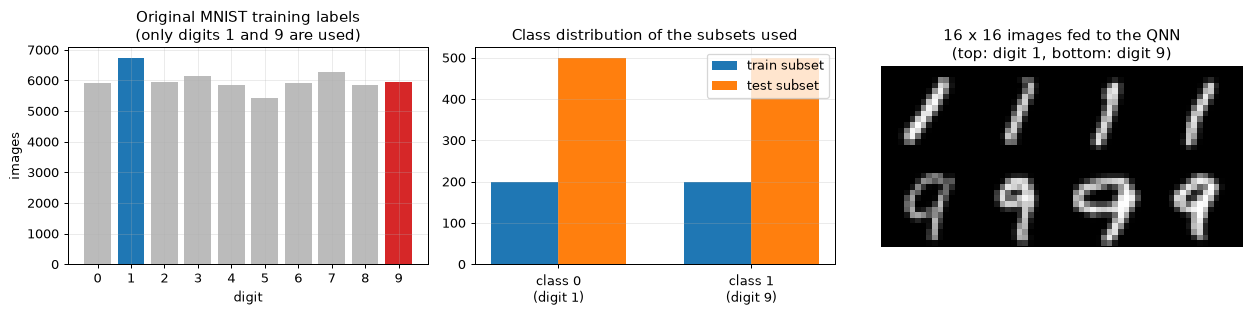

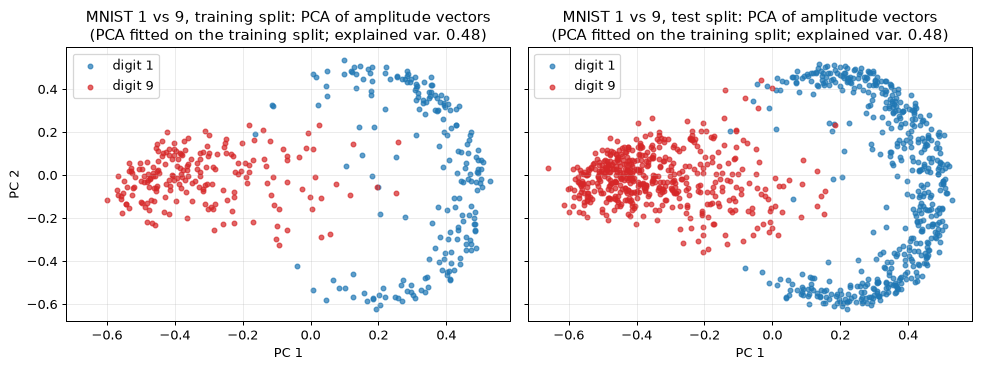

Amplitude encoding is used (no angle encoding), so no [0, pi]-scaled angle plot is needed; the circuit input is psi itself.


In [5]:
digits_all, counts_all = np.unique(raw_tr_y, return_counts=True)
print("Original MNIST training labels (digits) and counts:", dict(zip(digits_all.tolist(), counts_all.tolist())))
print("Original MNIST test labels (digits) and counts    :", dict(zip(*[a.tolist() for a in np.unique(raw_te_y, return_counts=True)])))
print("Feature names: pixel_r_c for r, c in 0..15 (row-major 16 x 16 intensity in [0,1]) -> 256 features per image")
print(f"Training subset shape {tuple(Xtr.shape)}   test subset shape {tuple(Xte.shape)}")
for nm, y in (("train", ytr_np), ("test", yte_np)):
    print(f"  {nm}: class 0 (digit 1) = {(y == 0).sum()}, class 1 (digit 9) = {(y == 1).sum()}")

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
cols = ["#bbbbbb"] * 10; cols[1] = "tab:blue"; cols[9] = "tab:red"
ax[0].bar(digits_all, counts_all, color=cols); ax[0].set_xticks(range(10))
ax[0].set_title("Original MNIST training labels\n(only digits 1 and 9 are used)"); ax[0].set_xlabel("digit"); ax[0].set_ylabel("images")
w = 0.35
for k, (nm, y) in enumerate((("train subset", ytr_np), ("test subset", yte_np))):
    ax[1].bar(np.arange(2) + (k - 0.5) * w, [(y == 0).sum(), (y == 1).sum()], w, label=nm)
ax[1].set_xticks([0, 1]); ax[1].set_xticklabels(["class 0\n(digit 1)", "class 1\n(digit 9)"]); ax[1].legend(); ax[1].set_title("Class distribution of the subsets used")
# 28 x 28 originals vs the 16 x 16 versions that are encoded
ex = [np.where(ytr_np == c)[0][:4] for c in (0, 1)]
tile = np.concatenate([np.concatenate([Xtr_img[i] for i in e], 1) for e in ex], 0)
ax[2].imshow(tile, cmap="gray"); ax[2].grid(False); ax[2].set_xticks([]); ax[2].set_yticks([])
ax[2].set_title("16 x 16 images fed to the QNN\n(top: digit 1, bottom: digit 9)")
plt.tight_layout(); plt.show()

# 2-D scatter: PCA (fitted on the training split) of the amplitude vectors psi = x / ||x||
psi_tr = (Xtr / Xtr.norm(dim=1, keepdim=True)).numpy(); psi_te = (Xte / Xte.norm(dim=1, keepdim=True)).numpy()
pca = PCA(n_components=2, random_state=SEED).fit(psi_tr)
Ptr, Pte = pca.transform(psi_tr), pca.transform(psi_te)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2), sharex=True, sharey=True)
for a, P, y, ttl in ((ax[0], Ptr, ytr_np, "training split"), (ax[1], Pte, yte_np, "test split")):
    for c, nm, col in ((0, "digit 1", "tab:blue"), (1, "digit 9", "tab:red")):
        a.scatter(P[y == c, 0], P[y == c, 1], s=14, alpha=0.7, c=col, label=nm)
    a.set_title(f"MNIST 1 vs 9, {ttl}: PCA of amplitude vectors\n(PCA fitted on the training split; explained var. {pca.explained_variance_ratio_.sum():.2f})")
    a.set_xlabel("PC 1"); a.legend()
ax[0].set_ylabel("PC 2")
plt.tight_layout(); plt.show()
print("Amplitude encoding is used (no angle encoding), so no [0, pi]-scaled angle plot is needed; the circuit input is psi itself.")

## 2. The simulation engine (and how it is checked)

Training and attacking a 10-layer circuit hundreds of thousands of times needs a fast simulator with gradients. The engine below is a small batched **PyTorch state-vector simulator** for exactly the gates used here (`RY`, `Rot`, `CNOT`, controlled-`Rot`). Three facts make it trustworthy, and all three are asserted in the next section:

1. **Gate by gate equality with PennyLane.** The same circuit is emitted as PennyLane operations (`default.qubit`) and the outputs agree to about 1e-15 for both architectures (QNN and QCNN).
2. **Exact noise average.** Averaging the layer `RY(eta * beta)`, `eta ~ N(0, sigma^2)`, over the Gaussian gives the single-qubit channel `rho -> (1+lam)/2 rho + (1-lam)/2 Y rho Y` with `lam = exp(-beta^2 sigma^2 / 2)` (a dephasing channel in the Y basis, which is self-adjoint). Pushing the observable `Z_out` backwards through the whole circuit (the Heisenberg picture) therefore gives one fixed 256 x 256 Hermitian matrix `M` with `E_noise[<Z>] = psi^T M psi` for every input. `M` is compared with PennyLane's **density-matrix simulator `default.mixed`** (with `qml.PauliError('Y', p)` for the channel) and with a Monte-Carlo average of the sampled model.
3. **Layered fast path.** For the 8-qubit QNN each layer's fused single-qubit matrices `Rot_q @ RY_q(eta)` are combined by Kronecker products into two 16 x 16 matrices, which is mathematically identical to applying the gates one by one (checked against the generic path to 1e-15 in the assertion cell of the circuit section).

In [6]:
DT = torch.complex128
SQ2 = math.sqrt(2.0)

# ---------- single-qubit gate matrices (PennyLane conventions) ----------
def ry_mat(a):                                   # a: (...,) real -> (..., 2, 2)
    c, s = torch.cos(a / 2), torch.sin(a / 2)
    return torch.stack([torch.stack([c, -s], -1), torch.stack([s, c], -1)], -2).to(DT)

def rot_mat(phi, theta, omega):                  # qml.Rot(phi, theta, omega) = RZ(omega) RY(theta) RZ(phi)
    c, s = torch.cos(theta / 2), torch.sin(theta / 2)
    e = lambda a: torch.exp(1j * a.to(DT))
    m00 = e(-(phi + omega) / 2) * c
    m01 = -e((phi - omega) / 2) * s
    m10 = e(-(phi - omega) / 2) * s
    m11 = e((phi + omega) / 2) * c
    return torch.stack([torch.stack([m00, m01], -1), torch.stack([m10, m11], -1)], -2)

def ry_only(theta):  return ry_mat(theta)
def rz_only(a):
    e = torch.exp(-0.5j * a.to(DT)); z = torch.zeros_like(e)
    return torch.stack([torch.stack([e, z], -1), torch.stack([z, e.conj()], -1)], -2)

YMAT = torch.tensor([[0, -1j], [1j, 0]], dtype=DT)

def crot_mat(phi, theta, omega):                 # controlled-Rot: block-diag(I, Rot)
    M = torch.zeros(4, 4, dtype=DT); M[0, 0] = 1; M[1, 1] = 1
    M[2:, 2:] = rot_mat(phi, theta, omega)
    return M

_CNOT_AB = torch.tensor([[1, 0, 0, 0], [0, 1, 0, 0], [0, 0, 0, 1], [0, 0, 1, 0]], dtype=DT)   # control = first qubit
_CNOT_BA = torch.tensor([[1, 0, 0, 0], [0, 0, 0, 1], [0, 0, 1, 0], [0, 1, 0, 0]], dtype=DT)   # control = second qubit

def conv_mat(theta, i):
    """4x4 unitary of the QCNN convolution block on qubits (a, b), the product of the 10 gates
    Rot(a) Rot(b) | CNOT(a,b) | RY(a) RZ(b) | CNOT(b,a) | RY(a) | CNOT(a,b) | Rot(a) Rot(b)  (15 parameters theta[i:i+15])."""
    I2 = torch.eye(2, dtype=DT)
    rot = lambda j: rot_mat(theta[j], theta[j + 1], theta[j + 2])
    M = torch.kron(rot(i), rot(i + 3))
    M = _CNOT_AB @ M
    M = torch.kron(ry_mat(theta[i + 6]), rz_only(theta[i + 7])) @ M
    M = _CNOT_BA @ M
    M = torch.kron(ry_mat(theta[i + 8]), I2) @ M
    M = _CNOT_AB @ M
    return torch.kron(rot(i + 9), rot(i + 12)) @ M

# ---------- circuit description ----------
class Circuit:
    """A circuit is a list of ops. Parameters: `theta` (flat vector of gate angles) and `beta` (one noise coefficient per
    noise layer). Ops:  ('noise', g, qubits)  RY(eta * beta[g]) on each listed qubit, eta ~ N(0, sigma^2), fresh per sample
                        ('rot', q, i)         qml.Rot(theta[i], theta[i+1], theta[i+2]) on qubit q
                        ('ry', q, i) / ('rz', q, i)   single rotation with angle theta[i]
                        ('ring', qubits)      CNOT(q0,q1) CNOT(q1,q2) ... CNOT(q_last,q0) in that order
                        ('cnot', c, t)        CNOT
                        ('crot', c, t, i)     controlled Rot(theta[i:i+3]) (control c, target t)
                        ('block', a, b, i)    QCNN convolution unitary on (a, b), 15 parameters (fused product of 10 gates)
    The output is <Z> on `out` qubit; qubit 0 is the most significant bit (PennyLane ordering)."""
    def __init__(self, n, ops, n_theta, n_noise, out=0, name=""):
        self.n, self.ops, self.n_theta, self.n_noise, self.out, self.name = n, ops, n_theta, n_noise, out, name
        self.dim = 2 ** n
        idx = np.arange(self.dim)
        self._ring = {}
        for op in ops:
            if op[0] == "ring":
                qs = list(op[1])
                if tuple(qs) in self._ring: continue
                f = np.zeros(self.dim, dtype=np.int64)
                for b in idx:
                    bits = [(b >> (n - 1 - q)) & 1 for q in range(n)]
                    for k in range(len(qs)):
                        c, t = qs[k], qs[(k + 1) % len(qs)]
                        bits[t] ^= bits[c]
                    f[b] = sum(bit << (n - 1 - q) for q, bit in enumerate(bits))
                finv = np.argsort(f)
                self._ring[tuple(qs)] = (torch.tensor(f), torch.tensor(finv))
        self.noise_groups = [op for op in ops if op[0] == "noise"]
        assert len(self.noise_groups) == n_noise
        # layered fast path: detect  noise(all qubits), rot x n (consecutive parameters), ring(all qubits)  repeated
        self.layered = None
        step = n + 2
        if n % 2 == 0 and len(ops) % step == 0 and len(ops) > 0:
            lay, ok = [], True
            for s in range(0, len(ops), step):
                blk = ops[s:s + step]
                ok &= blk[0][0] == "noise" and tuple(blk[0][2]) == tuple(range(n))
                ok &= all(blk[1 + q][0] == "rot" and blk[1 + q][1] == q and blk[1 + q][2] == blk[1][2] + 3 * q for q in range(n))
                ok &= blk[-1][0] == "ring" and tuple(blk[-1][1]) == tuple(range(n))
                if not ok: break
                lay.append((blk[0][1], blk[1][2], tuple(blk[-1][1])))
            if ok: self.layered = lay

    # -- pure-state simulation of one noise realisation for a batch of inputs --
    def forward_state(self, psi, theta, beta, eta=None, sigma=1.0, gen=None, noise_on=True):
        """psi: (B, 2^n) complex128 amplitude-encoded inputs; eta: optional dict {g: (B, len(qubits))} noise draws.
        Returns <Z_out> of shape (B,)."""
        B, n = psi.shape[0], self.n
        if self.layered is not None:                    # fast path for the layered QNN (same maths, fewer tensor ops)
            return self._forward_layered(psi, theta, beta, eta, sigma, gen, noise_on)
        st = psi
        for op in self.ops:
            k = op[0]
            if k == "noise":
                if not noise_on: continue
                g, qs = op[1], op[2]
                if eta is not None and g in eta:
                    e = eta[g]
                else:
                    e = torch.randn(B, len(qs), dtype=torch.float64, generator=gen) * sigma
                ang = e * beta[g]
                for j, q in enumerate(qs):
                    st = _apply1(st, ry_mat(ang[:, j]), q, n)
            elif k == "rot":
                st = _apply1(st, rot_mat(theta[op[2]], theta[op[2] + 1], theta[op[2] + 2]), op[1], n)
            elif k == "ry":
                st = _apply1(st, ry_mat(theta[op[2]]), op[1], n)
            elif k == "rz":
                st = _apply1(st, rz_only(theta[op[2]]), op[1], n)
            elif k == "ring":
                st = st[:, self._ring[tuple(op[1])][1]]
            elif k == "cnot":
                st = _apply2(st, _CNOT, op[1], op[2], n)
            elif k == "crot":
                st = _apply2(st, crot_mat(theta[op[3]], theta[op[3] + 1], theta[op[3] + 2]), op[1], op[2], n)
            elif k == "block":
                st = _apply2(st, conv_mat(theta, op[3]), op[1], op[2], n)
            else:
                raise ValueError(k)
        p = (st.conj() * st).real.reshape(B, 2 ** self.out, 2, 2 ** (n - self.out - 1)).sum((1, 3))
        return p[:, 0] - p[:, 1]

    def _forward_layered(self, psi, theta, beta, eta, sigma, gen, noise_on):
        """Layered QNN: every layer is  noise RY on all qubits -> Rot on all qubits -> CNOT ring. The 8 fused single-qubit
        matrices Rot_q @ RY_q are combined by Kronecker products into one 16x16 matrix for qubits 0-3 and one for 4-7, so a
        layer costs two batched matrix products instead of sixteen gate applications. Identical to the generic path."""
        B, n = psi.shape[0], self.n
        h = n // 2
        S = psi.reshape(B, 2 ** h, 2 ** (n - h))
        L = len(self.layered)
        gs = torch.tensor([g for (g, _, _) in self.layered])
        th = theta[torch.tensor([[[i0 + 3 * q + k for k in range(3)] for q in range(n)] for (_, i0, _) in self.layered])]   # (L,n,3)
        R = rot_mat(th[..., 0], th[..., 1], th[..., 2])                                            # (L,n,2,2) all layers at once
        if noise_on:
            if eta is not None:
                e = torch.stack([eta[int(g)] for g in gs], 1)                                         # (B,L,n)
            else:
                e = torch.randn(B, L, n, dtype=torch.float64, generator=gen) * sigma
            F = R[None] @ ry_mat(e * beta[gs][None, :, None])                                       # (B,L,n,2,2): Rot_q @ RY_q(noise)
        else:
            F = R[None].expand(B, -1, -1, -1, -1)
        KA = _kron_batch(F[:, :, :h].reshape(B * L, h, 2, 2)).reshape(B, L, 2 ** h, 2 ** h)
        KB = _kron_batch(F[:, :, h:].reshape(B * L, n - h, 2, 2)).reshape(B, L, 2 ** (n - h), 2 ** (n - h))
        KAs, KBs = KA.unbind(1), KB.unbind(1)
        for l, (_, _, ring) in enumerate(self.layered):
            S = KAs[l] @ S @ KBs[l].transpose(1, 2)
            S = S.reshape(B, -1)[:, self._ring[ring][1]].reshape(B, 2 ** h, 2 ** (n - h))
        st = S.reshape(B, -1)
        p = (st.conj() * st).real.reshape(B, 2 ** self.out, 2, 2 ** (n - self.out - 1)).sum((1, 3))
        return p[:, 0] - p[:, 1]

    # -- exact noise-averaged observable (Heisenberg picture) --
    def heisenberg_matrix(self, theta, beta, sigma=1.0, noise_on=True):
        """M such that  E_noise[<Z_out>(psi)] = psi^dagger M psi  for every input state psi (exact, no sampling).
        The Gaussian-averaged layer RY(eta*beta) is the single-qubit channel  rho -> (1+lam)/2 rho + (1-lam)/2 Y rho Y,
        lam = exp(-beta^2 sigma^2 / 2)  (Y-dephasing), which is self-adjoint, so it is applied to the observable directly."""
        n = self.n
        bit = (torch.arange(self.dim) >> (n - 1 - self.out)) & 1
        O = torch.diag((1 - 2 * bit).to(DT))
        T = O.reshape((2,) * (2 * n))
        for op in reversed(self.ops):
            k = op[0]
            if k == "noise":
                if not noise_on: continue
                lam = torch.exp(-(beta[op[1]] * sigma) ** 2 / 2)
                for q in op[2]:
                    Ty = _conj1(T, YMAT, q, n)
                    T = (1 + lam) / 2 * T + (1 - lam) / 2 * Ty
            elif k == "rot":
                T = _conj1(T, rot_mat(theta[op[2]], theta[op[2] + 1], theta[op[2] + 2]), op[1], n)
            elif k == "ry":
                T = _conj1(T, ry_mat(theta[op[2]]), op[1], n)
            elif k == "rz":
                T = _conj1(T, rz_only(theta[op[2]]), op[1], n)
            elif k == "ring":
                f = self._ring[tuple(op[1])][0]
                T = T.reshape(self.dim, self.dim)[f][:, f].reshape((2,) * (2 * n))
            elif k == "cnot":
                T = _conj2(T, _CNOT, op[1], op[2], n)
            elif k == "crot":
                T = _conj2(T, crot_mat(theta[op[3]], theta[op[3] + 1], theta[op[3] + 2]), op[1], op[2], n)
            elif k == "block":
                T = _conj2(T, conv_mat(theta, op[3]), op[1], op[2], n)
        return T.reshape(self.dim, self.dim)

def _kron_batch(M):
    """M: (B, m, d, d), m a power of two -> (B, d^m, d^m) Kronecker product of the m matrices (first = most significant)."""
    while M.shape[1] > 1:
        A, Bm = M[:, 0::2], M[:, 1::2]
        d = A.shape[-1]
        M = (A[..., :, None, :, None] * Bm[..., None, :, None, :]).reshape(M.shape[0], A.shape[1], d * d, d * d)
    return M[:, 0]

_CNOT = torch.tensor([[1, 0, 0, 0], [0, 1, 0, 0], [0, 0, 0, 1], [0, 0, 1, 0]], dtype=DT)

def _apply1(st, U, q, n):                                    # st (B, 2^n); U (2,2) or (B,2,2)
    B = st.shape[0]
    s4 = st.reshape(B, 2 ** q, 2, 2 ** (n - q - 1))
    if U.dim() == 2:
        out = torch.einsum("ij,bajc->baic", U, s4)
    else:
        out = torch.einsum("bij,bajc->baic", U, s4)
    return out.reshape(B, -1)

def _apply2(st, U4, a, b, n):                                # U4 (4,4), control/first qubit a, second qubit b
    B = st.shape[0]
    t = st.reshape((B,) + (2,) * n)
    U = U4.reshape(2, 2, 2, 2)                               # (out_a, out_b, in_a, in_b)
    t = torch.tensordot(U, t, dims=([2, 3], [1 + a, 1 + b]))  # axes of t now: [out_a, out_b, B, other qubits in order]
    rest = [i for i in range(n) if i not in (a, b)]
    order = [None] * (n + 1)
    order[0] = 2                                              # batch axis first
    rem = iter(range(3, 3 + len(rest)))
    for qq in range(n):
        order[1 + qq] = 0 if qq == a else (1 if qq == b else next(rem))
    return t.permute(*order).reshape(B, -1)

def _conj1(T, U, q, n):                                      # T -> (U^dag (.) U) on row/col axes of qubit q (T has 2n axes of size 2)
    T = torch.movedim(torch.tensordot(U.conj().T, T, dims=([1], [q])), 0, q)
    T = torch.movedim(torch.tensordot(U.T, T, dims=([1], [n + q])), 0, n + q)
    return T

def _conj2(T, U4, a, b, n):
    U = U4.reshape(2, 2, 2, 2)
    Ud = U4.conj().T.reshape(2, 2, 2, 2)
    T = torch.tensordot(Ud, T, dims=([2, 3], [a, b]))
    T = torch.movedim(T, (0, 1), (a, b))
    UT = U4.T.reshape(2, 2, 2, 2)
    T = torch.tensordot(UT, T, dims=([2, 3], [n + a, n + b]))
    T = torch.movedim(T, (0, 1), (n + a, n + b))
    return T

# ---------- the two architectures of the paper ----------
def build_qnn(n=8, depth=10, noise=True):
    """Fig. 3(a): P layers; layer l = [noise layer] + rotation unit (Rot on every qubit) + entangling unit (CNOT ring)."""
    ops, i = [], 0
    for l in range(depth):
        ops.append(("noise", l, tuple(range(n))))
        for q in range(n):
            ops.append(("rot", q, i)); i += 3
        ops.append(("ring", tuple(range(n))))
    return Circuit(n, ops, i, depth, out=0, name=f"QNN (n={n}, depth={depth})")

def build_qcnn(n=8):
    """Fig. 3(b): convolution + pooling stages; a noise layer is added before every convolutional layer."""
    ops, i, g, act = [], 0, 0, list(range(n))
    while len(act) > 1:
        ops.append(("noise", g, tuple(act))); g += 1
        for parity in (0, 1):                                    # convolution on neighbouring pairs, even pairs then odd pairs
            for k in range(parity, len(act) - 1, 2):
                a, b = act[k], act[k + 1]
                ops.append(("block", a, b, i)); i += 15       # 15-parameter two-qubit convolution unitary (see conv_mat)
        keep = []
        for k in range(0, len(act) - 1, 2):                      # pooling: controlled rotation, then discard the control qubit
            ops.append(("crot", act[k], act[k + 1], i)); i += 3
            keep.append(act[k + 1])
        if len(act) % 2: keep.append(act[-1])
        act = keep
    ops.append(("rot", act[0], i)); i += 3
    return Circuit(n, ops, i, g, out=act[0], name=f"QCNN (n={n})")

In [7]:
import pennylane as qml

def pl_apply(circ, x, theta, beta, eta=None, sigma=1.0, channel=False):
    """Emit the gate list of `circ` as PennyLane operations (amplitude embedding first, then every op in order).
    channel=False: noise layers are RY gates with the angles eta[g][j]*beta[g] (one noise realisation).
    channel=True : noise layers are the averaged channel PauliError('Y', p) on default.mixed."""
    n = circ.n
    qml.AmplitudeEmbedding(x, wires=range(n), normalize=True)
    for op in circ.ops:
        k = op[0]
        if k == "noise":
            g, qs = op[1], op[2]
            for j, q in enumerate(qs):
                if channel:
                    lam = np.exp(-(float(beta[g]) * sigma) ** 2 / 2)
                    qml.PauliError("Y", (1 - lam) / 2, wires=q)
                else:
                    qml.RY(float(eta[g][j]) * float(beta[g]), wires=q)
        elif k == "rot":
            qml.Rot(theta[op[2]], theta[op[2] + 1], theta[op[2] + 2], wires=op[1])
        elif k == "ry":
            qml.RY(theta[op[2]], wires=op[1])
        elif k == "rz":
            qml.RZ(theta[op[2]], wires=op[1])
        elif k == "ring":
            qs = list(op[1])
            for a in range(len(qs)):
                qml.CNOT(wires=[qs[a], qs[(a + 1) % len(qs)]])
        elif k == "cnot":
            qml.CNOT(wires=[op[1], op[2]])
        elif k == "block":                                   # the 10 elementary gates whose product is conv_mat
            a, b, i = op[1], op[2], op[3]
            qml.Rot(theta[i], theta[i + 1], theta[i + 2], wires=a); qml.Rot(theta[i + 3], theta[i + 4], theta[i + 5], wires=b)
            qml.CNOT(wires=[a, b]); qml.RY(theta[i + 6], wires=a); qml.RZ(theta[i + 7], wires=b)
            qml.CNOT(wires=[b, a]); qml.RY(theta[i + 8], wires=a); qml.CNOT(wires=[a, b])
            qml.Rot(theta[i + 9], theta[i + 10], theta[i + 11], wires=a); qml.Rot(theta[i + 12], theta[i + 13], theta[i + 14], wires=b)
        elif k == "crot":
            qml.CRot(theta[op[3]], theta[op[3] + 1], theta[op[3] + 2], wires=[op[1], op[2]])

def pl_qnode(circ, channel=False, sigma=1.0):
    dev = qml.device("default.mixed" if channel else "default.qubit", wires=circ.n)
    @qml.qnode(dev)
    def f(x, theta, beta, eta=None):
        pl_apply(circ, x, theta, beta, eta=eta, sigma=sigma, channel=channel)
        return qml.expval(qml.PauliZ(circ.out))
    return f

## Quantum Circuit Architecture

This section draws **the circuits that are actually executed**, using PennyLane's `qml.draw_mpl` on the real QNodes built from the same gate list as the PyTorch engine, prints qubit count, depth and trainable-parameter count, and asserts that the engine and PennyLane agree.

Encoding: `qml.AmplitudeEmbedding` of the 256 normalised pixels onto 8 qubits (no trainable parameters). Parametrised gates: `RY(eta * beta_l)` noise layer (the noise angles are drawn at run time, `beta_l` trainable) and `Rot(phi, theta, omega)` on every qubit. Entanglement: a ring of CNOTs `0->1, 1->2, ..., 7->0`. Measurement: expectation of `Z` on qubit 0. The paper's Fig. 3 gives the structure, not the exact CNOT pattern (documented in the table above).

In [8]:
CIRC_QNN = build_qnn(N_QUBITS, DEPTH)
CIRC_QCNN = build_qcnn(N_QUBITS)
g = np.random.default_rng(SEED)

def circuit_stats(circ, x, theta, beta, eta):
    f = pl_qnode(circ)
    specs = qml.specs(f)(x, theta, beta, eta)
    res = specs["resources"] if isinstance(specs, dict) else specs.resources
    n_gates = int(res.num_gates)
    return f, circ.n, int(res.depth), n_gates

x0 = g.uniform(0, 1, 256)
for circ in (CIRC_QNN, CIRC_QCNN):
    th = g.uniform(0, 2 * np.pi, circ.n_theta); be = np.full(circ.n_noise, BETA0)
    et = {gi: g.normal(0, SIGMA, len(op[2])) for gi, op in enumerate(circ.noise_groups)}
    f, nw, depth, ng = circuit_stats(circ, x0, th, be, et)
    print(f"{circ.name}: {nw} qubits, depth {depth} (noise layers as RY gates), {ng} gates, "
          f"{circ.n_theta} trainable rotation angles + {circ.n_noise} trainable noise coefficients beta = {circ.n_theta + circ.n_noise} trainable parameters")

QNN (n=8, depth=10): 8 qubits, depth 101 (noise layers as RY gates), 241 gates, 240 trainable rotation angles + 10 trainable noise coefficients beta = 250 trainable parameters
QCNN (n=8): 8 qubits, depth 43 (noise layers as RY gates), 133 gates, 189 trainable rotation angles + 3 trainable noise coefficients beta = 192 trainable parameters


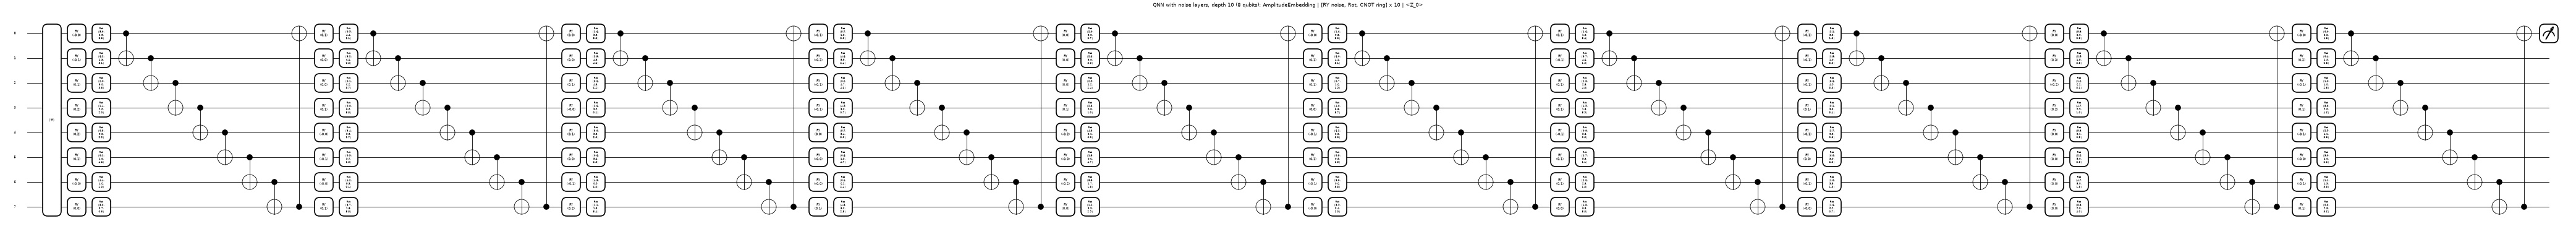

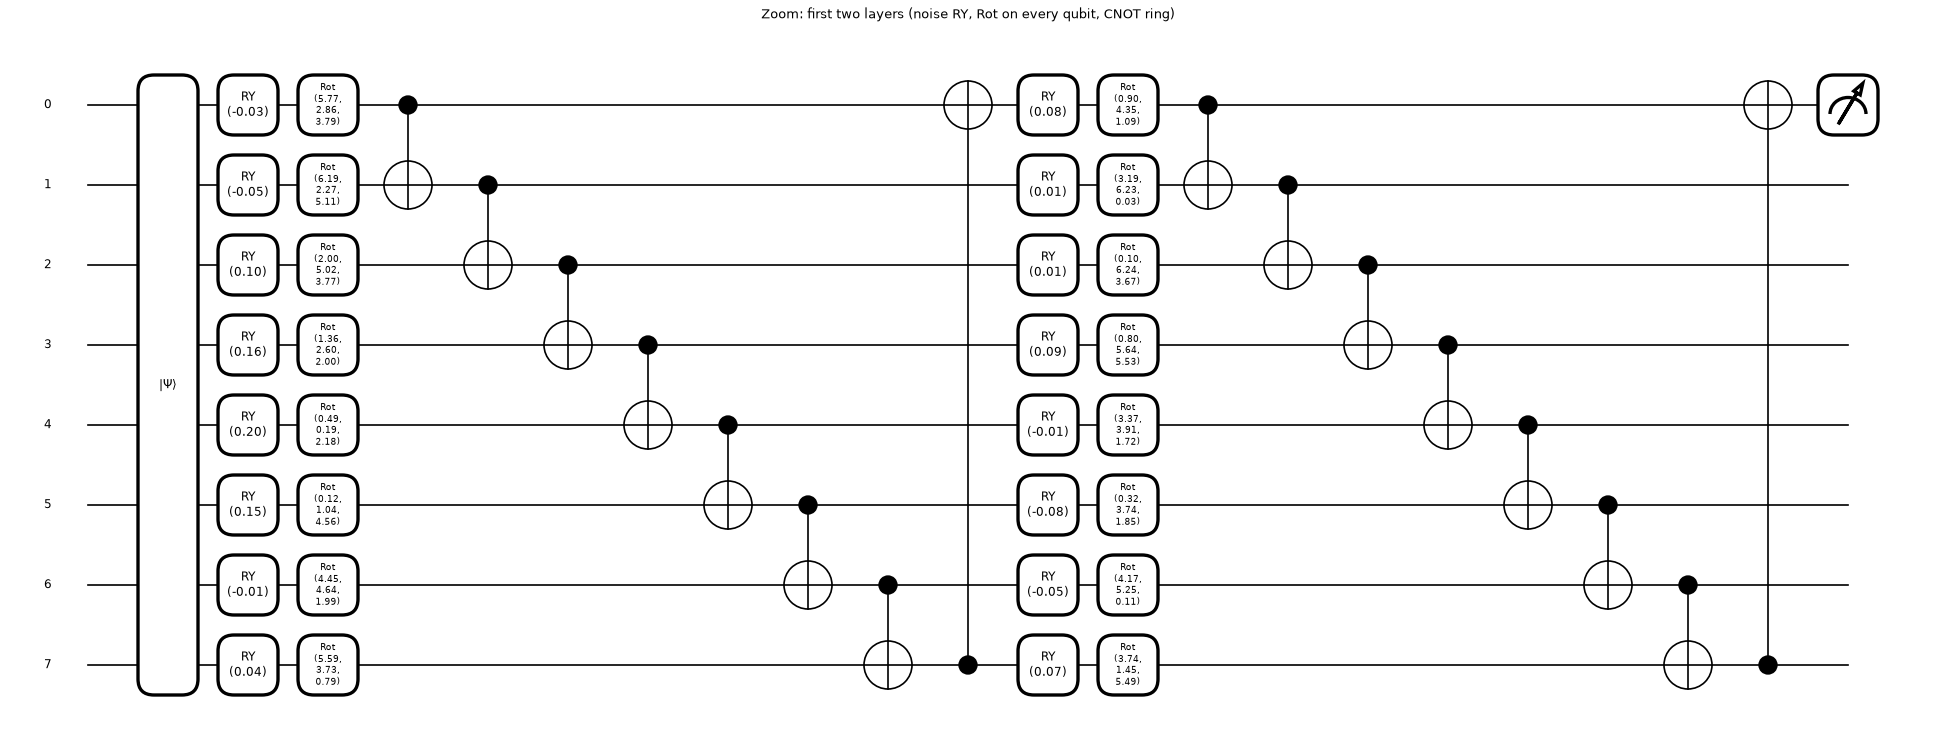

In [9]:
# Drawing 1: the QNN of Fig. 3(a), depth 10, exactly as executed (noise angles eta*beta are shown as numbers for one noise draw)
th = g.uniform(0, 2 * np.pi, CIRC_QNN.n_theta); be = np.full(CIRC_QNN.n_noise, BETA0)
et = {gi: g.normal(0, SIGMA, 8) for gi in range(CIRC_QNN.n_noise)}
f = pl_qnode(CIRC_QNN)
fig, ax = qml.draw_mpl(f, decimals=1, fontsize=9)(x0, th, be, et)
fig.set_size_inches(min(fig.get_size_inches()[0], 120), fig.get_size_inches()[1]); fig.set_dpi(40)
ax.set_title("QNN with noise layers, depth 10 (8 qubits): AmplitudeEmbedding | [RY noise, Rot, CNOT ring] x 10 | <Z_0>", fontsize=14)
plt.show()

# Drawing 2: the first two layers at readable size (same builder, depth 2)
c2 = build_qnn(N_QUBITS, 2)
fig, ax = qml.draw_mpl(pl_qnode(c2), decimals=2, fontsize=11)(x0, th[:c2.n_theta], be[:2], {gi: et[gi] for gi in range(2)})
fig.set_dpi(80); ax.set_title("Zoom: first two layers (noise RY, Rot on every qubit, CNOT ring)"); plt.show()

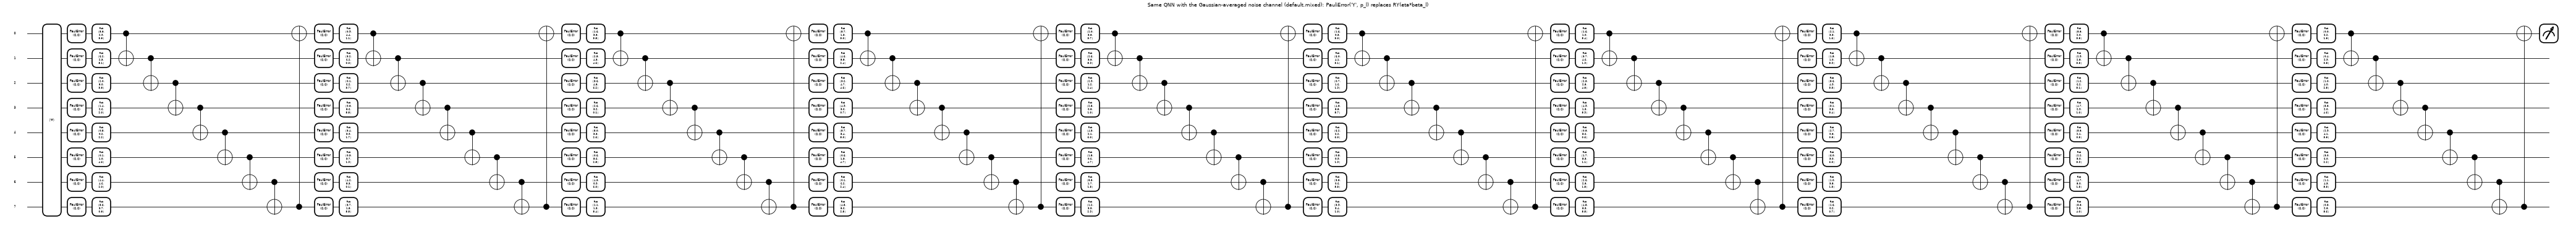

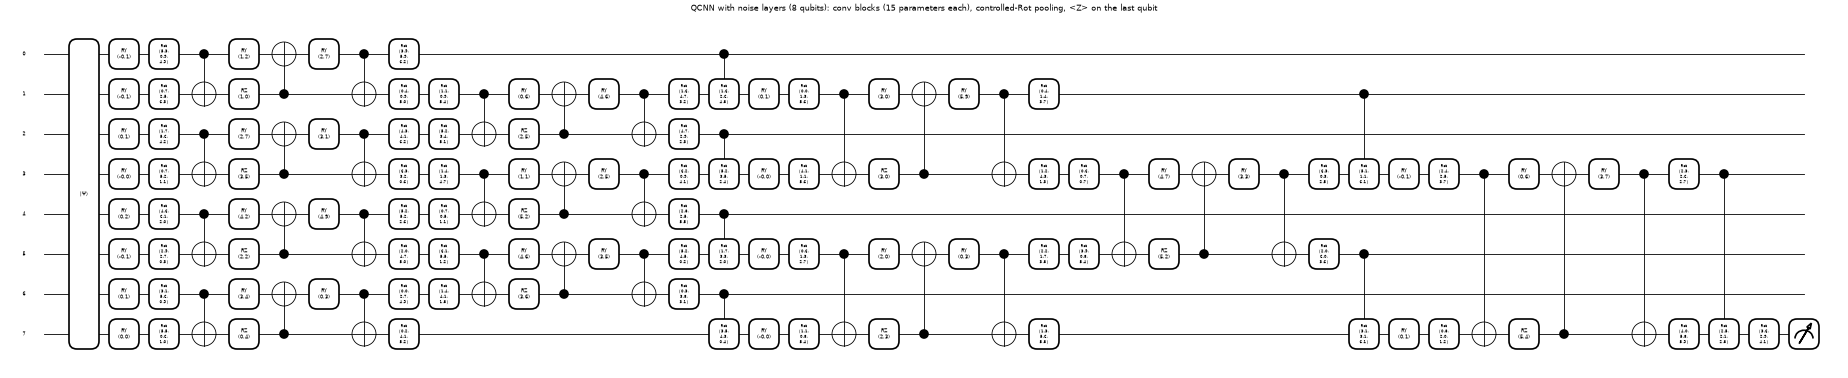

In [10]:
# Drawing 3: the exact noise-averaged circuit on the density-matrix simulator (the noise layer becomes the channel PauliError('Y', p)).
fm = pl_qnode(CIRC_QNN, channel=True, sigma=SIGMA)
fig, ax = qml.draw_mpl(fm, decimals=1, fontsize=9)(x0, th, be)
fig.set_size_inches(min(fig.get_size_inches()[0], 120), fig.get_size_inches()[1]); fig.set_dpi(40)
ax.set_title("Same QNN with the Gaussian-averaged noise channel (default.mixed): PauliError('Y', p_l) replaces RY(eta*beta_l)", fontsize=14)
plt.show()

# Drawing 4: the QCNN of Fig. 3(b), exactly as executed (noise layer before each of the 3 conv+pool stages)
thq = g.uniform(0, 2 * np.pi, CIRC_QCNN.n_theta); beq = np.full(CIRC_QCNN.n_noise, BETA0)
etq = {gi: g.normal(0, SIGMA, len(op[2])) for gi, op in enumerate(CIRC_QCNN.noise_groups)}
fq = pl_qnode(CIRC_QCNN)
fig, ax = qml.draw_mpl(fq, decimals=1, fontsize=9)(x0, thq, beq, etq)
fig.set_size_inches(min(fig.get_size_inches()[0], 120), fig.get_size_inches()[1]); fig.set_dpi(40)
ax.set_title("QCNN with noise layers (8 qubits): conv blocks (15 parameters each), controlled-Rot pooling, <Z> on the last qubit", fontsize=14)
plt.show()

In [11]:
# Equivalence assertions: the PyTorch engine used for all training/attacks == PennyLane on the same gate list.
gg = np.random.default_rng(1)
for circ in (CIRC_QNN, CIRC_QCNN):
    th_ = gg.uniform(0, 2 * np.pi, circ.n_theta); be_ = gg.uniform(0.1, 1.2, circ.n_noise)
    xs = gg.uniform(0, 1, (4, 256)); psi_ = torch.tensor(xs / np.linalg.norm(xs, axis=1, keepdims=True), dtype=DT)
    et_ = {gi: torch.tensor(gg.normal(0, SIGMA, (4, len(op[2])))) for gi, op in enumerate(circ.noise_groups)}
    z_t = circ.forward_state(psi_, torch.tensor(th_), torch.tensor(be_), eta=et_).numpy()
    f_ = pl_qnode(circ)
    z_p = np.array([float(f_(xs[b], th_, be_, {gi: et_[gi][b].numpy() for gi in et_})) for b in range(4)])
    err1 = np.abs(z_t - z_p).max()
    # exact noise average: Heisenberg matrix vs default.mixed density-matrix simulation with PauliError channels
    M_ = circ.heisenberg_matrix(torch.tensor(th_), torch.tensor(be_), SIGMA)
    z_ex = torch.einsum("bi,ij,bj->b", psi_.conj(), M_, psi_).real.numpy()
    fmx = pl_qnode(circ, channel=True, sigma=SIGMA)
    z_dm = np.array([float(fmx(xs[b], th_, be_)) for b in range(2)])
    err2 = np.abs(z_ex[:2] - z_dm).max()
    # Monte-Carlo average of the sampled noisy model -> exact value
    big = psi_[:1].repeat(40000, 1)
    zz = circ.forward_state(big, torch.tensor(th_), torch.tensor(be_), sigma=SIGMA, gen=torch.Generator().manual_seed(7))
    se = zz.std().item() / math.sqrt(len(zz)); dev = abs(zz.mean().item() - z_ex[0])
    print(f"{circ.name}: |engine - PennyLane default.qubit| = {err1:.1e};  |Heisenberg M - PennyLane default.mixed| = {err2:.1e};  "
          f"MC mean {zz.mean().item():+.5f} vs exact {z_ex[0]:+.5f} ({dev / se:.1f} standard errors)")
    assert err1 < 1e-10, "engine differs from PennyLane"
    assert err2 < 1e-10, "exact noise average differs from the density-matrix simulator"
    assert dev < 5 * se, "sampled noise average does not converge to the exact channel"
# the fast layered path equals the generic gate-by-gate path
th_ = torch.tensor(gg.uniform(0, 2 * np.pi, CIRC_QNN.n_theta)); be_ = torch.tensor(gg.uniform(0.1, 1.2, CIRC_QNN.n_noise))
psi_ = torch.tensor(gg.normal(size=(5, 256)), dtype=DT); psi_ = psi_ / psi_.norm(dim=1, keepdim=True)
et_ = {gi: torch.tensor(gg.normal(0, SIGMA, (5, 8))) for gi in range(CIRC_QNN.n_noise)}
lay = CIRC_QNN.layered; a = CIRC_QNN.forward_state(psi_, th_, be_, eta=et_)
CIRC_QNN.layered = None; b = CIRC_QNN.forward_state(psi_, th_, be_, eta=et_); CIRC_QNN.layered = lay
print("layered fast path vs generic gate-by-gate path:", f"{(a - b).abs().max().item():.1e}")
assert (a - b).abs().max().item() < 1e-10
print("All equivalence assertions passed.")

QNN (n=8, depth=10): |engine - PennyLane default.qubit| = 2.2e-16;  |Heisenberg M - PennyLane default.mixed| = 3.1e-15;  MC mean +0.00101 vs exact +0.00130 (1.0 standard errors)


QCNN (n=8): |engine - PennyLane default.qubit| = 7.2e-16;  |Heisenberg M - PennyLane default.mixed| = 2.1e-14;  MC mean +0.08342 vs exact +0.08321 (0.7 standard errors)


layered fast path vs generic gate-by-gate path: 3.3e-16
All equivalence assertions passed.


## 3. Models, training (Algorithm 1) and attacks

* `QModel` is a trained noisy QNN. `z(x)` runs one noise realisation per input; `z_exact(x)` is the exact noise-averaged output `psi^T M psi`.
* `train_qnn` is Algorithm 1: Adam on the rotation angles and (when noise layers are on) the coefficients `beta`; with `combined=True` each mini-batch gets BIM adversarial examples crafted against the *current noisy model* (one fresh noise draw per gradient call, which is the attacker the paper assumes) and the loss `L' = gamma L(adv) + (1-gamma) L(clean)`.
* `craft` makes FGSM / BIM / PGD / MIM examples inside the L-infinity ball of radius `eps` around the pixels, clipped to [0,1], with three ways to obtain the gradient of a noisy model: `single` (one noise draw), `eot` (mean loss over `K` draws) and `exact` (gradient of the loss of the exact noise-averaged output).
* `predict_z` is Algorithm 2: `exact` is the `J -> infinity` limit, `draw` is one noise draw per input.

In [12]:
def encode(x):
    """Amplitude encoding: 256 pixels -> normalised 8-qubit state vector. Differentiable, so attacks see the normalisation."""
    return (x / x.norm(dim=1, keepdim=True).clamp_min(1e-12)).to(DT)

def ce_from_z(z, y):
    """Binary cross-entropy of the read-out. P(class 1) = P(qubit = |1>) = (1 - <Z>)/2, so class 1 <-> <Z> < 0."""
    p1 = ((1 - z) / 2).clamp(1e-7, 1 - 1e-7)
    return -(y * torch.log(p1) + (1 - y) * torch.log(1 - p1))

class QModel:
    """A trained noisy QNN: circuit + parameters. noise_on switches the noise layers on/off at inference and attack time."""
    def __init__(self, circ, theta, beta, sigma, noise_on=True, name=""):
        self.circ, self.theta, self.beta, self.sigma, self.noise_on, self.name = circ, theta, beta, sigma, noise_on, name
        self._M = None
    def with_noise(self, on, name=None):
        return QModel(self.circ, self.theta, self.beta, self.sigma, on, name or self.name)
    def z(self, x, gen=None):                       # one noise realisation per row of x (grad flows to x)
        return self.circ.forward_state(encode(x), self.theta, self.beta, sigma=self.sigma, gen=gen, noise_on=self.noise_on)
    def M(self):                                    # exact noise-averaged observable (Heisenberg picture), cached
        if self._M is None:
            with torch.no_grad():
                self._M = self.circ.heisenberg_matrix(self.theta.detach(), self.beta.detach(), self.sigma, noise_on=self.noise_on)
        return self._M
    def z_exact(self, x):                           # E_noise[<Z>] = psi^T Re(M) psi : deterministic, differentiable in x
        psi = encode(x)
        return torch.einsum("bi,ij,bj->b", psi.conj(), self.M(), psi).real

def loss_fn_for(model, y, mode, K=1, gen=None):
    """Returns f(x) -> per-sample loss for the attacker's gradient.
       'single': one fresh noise draw per gradient call (what the paper's attacker does)
       'eot'   : expectation over transformation, mean loss over K noise draws
       'exact' : loss of the exact noise-averaged output (K -> infinity, no sampling at all)"""
    if mode == "exact" and model.noise_on:
        return lambda x: ce_from_z(model.z_exact(x), y)
    if mode == "eot" and model.noise_on:
        def f(x):
            B = x.shape[0]
            z = model.z(x.repeat_interleave(K, 0), gen=gen).reshape(B, K)
            return ce_from_z(z, y[:, None]).mean(1)
        return f
    return lambda x: ce_from_z(model.z(x, gen=gen), y)

def attack_linf(loss_f, x0, eps, iters, step, momentum=0.0):
    """FGSM (iters=1, step=eps), BIM/PGD (iters>1): x <- clip(x + step*sign(grad)) inside the L_inf ball and the pixel range [0,1].
    momentum>0 gives MIM (Dong et al.)."""
    x = x0.clone(); g_acc = torch.zeros_like(x0)
    for _ in range(iters):
        x = x.detach().requires_grad_(True)
        g, = torch.autograd.grad(loss_f(x).sum(), x)
        if momentum > 0:
            g_acc = momentum * g_acc + g / g.abs().sum(1, keepdim=True).clamp_min(1e-12); g = g_acc
        x = x.detach() + step * g.sign()
        x = torch.min(torch.max(x, x0 - eps), x0 + eps).clamp(0, 1)
    return x.detach()

def make_attack(kind, eps):
    if kind == "fgsm": return dict(iters=1, step=eps)
    if kind == "bim":  return dict(iters=BIM_ITERS, step=eps / BIM_ITERS)      # paper: 3 iterations of step 0.05 = eps/3 at eps = 0.15
    if kind == "pgd":  return dict(iters=PGD_ITERS, step=2.5 * eps / PGD_ITERS)
    if kind == "mim":  return dict(iters=BIM_ITERS, step=eps / BIM_ITERS, momentum=1.0)
    raise ValueError(kind)

def craft(model, x, y, kind, eps, mode, K=1, gen=None):
    return attack_linf(loss_fn_for(model, y, mode, K, gen), x, eps, **make_attack(kind, eps))

@torch.no_grad()
def predict_z(model, x, how="exact", J=1, gen=None, chunk=500):
    """how='exact': Algorithm 2 with J -> infinity (exact noise average); 'draw': one noise draw per sample (J = 1);
       'mc': mean of J noise draws. For a model with noise off all three coincide."""
    outs = []
    for i in range(0, len(x), chunk):
        xb = x[i:i + chunk]
        if not model.noise_on or how == "draw":
            outs.append(model.z(xb, gen=gen))
        elif how == "exact":
            outs.append(model.z_exact(xb))
        else:
            B = xb.shape[0]; outs.append(model.z(xb.repeat_interleave(J, 0), gen=gen).reshape(B, J).mean(1))
    return torch.cat(outs)

def acc_of(z, y):
    return float(((z < 0).to(torch.float64) == y).to(torch.float64).mean())

def accuracy(model, x, y, how="exact", gen=None, J=50):
    return acc_of(predict_z(model, x, how, J=J, gen=gen), y)

def train_qnn(circ, Xtr, ytr, *, noise, combined, sigma, epochs, lr, bs, eps, seed, gamma=0.5, beta0=0.25, name="", verbose=True):
    """Algorithm 1 of the paper. noise: noise layers on during training; combined: loss L' = gamma*L(adv) + (1-gamma)*L(clean)
    (eq. 9) with adversarial examples crafted by BIM against the current noisy model (one fresh noise draw per gradient call);
    otherwise the plain clean cross-entropy. Adam updates theta and (if noise) the noise coefficients beta."""
    g_np = np.random.default_rng(seed)
    gen = torch.Generator().manual_seed(seed)
    theta = torch.tensor(g_np.uniform(0, 2 * np.pi, circ.n_theta), requires_grad=True)       # CHOICE: uniform [0, 2pi)
    beta = torch.full((circ.n_noise,), beta0, dtype=torch.float64, requires_grad=True)
    opt = torch.optim.Adam([theta, beta] if noise else [theta], lr=lr)
    n = len(ytr); hist = []; t0 = time.time()
    for ep in range(epochs):
        perm = torch.tensor(g_np.permutation(n)); tot = 0.0
        for i in range(0, n, bs):
            idx = perm[i:i + bs]; xb, yb = Xtr[idx], ytr[idx]
            m = QModel(circ, theta, beta, sigma, noise_on=noise)
            if combined:
                xa = craft(QModel(circ, theta.detach(), beta.detach(), sigma, noise), xb, yb, "bim", eps, "single", gen=gen)
                loss = gamma * ce_from_z(m.z(xa, gen=gen), yb).mean() + (1 - gamma) * ce_from_z(m.z(xb, gen=gen), yb).mean()
            else:
                loss = ce_from_z(m.z(xb, gen=gen), yb).mean()
            opt.zero_grad(); loss.backward(); opt.step()
            tot += float(loss) * len(idx)
        hist.append(tot / n)
        if verbose and (ep + 1) % max(1, epochs // 5) == 0:
            print(f"  [{name}] epoch {ep + 1:>3}/{epochs}  loss {hist[-1]:.4f}  ({time.time() - t0:.0f}s)")
    return QModel(circ, theta.detach(), beta.detach(), sigma, noise_on=noise, name=name), hist

In [13]:
import torch.nn as nn

class NoisyMLP(nn.Module):
    """Classical counterpart of the paper's idea on the SAME inputs (the amplitude-normalised 256-vector, rescaled to unit RMS):
    a small MLP with a noise layer before every linear layer, h <- h + beta_l * eta * rms(h), eta ~ N(0,1), beta_l trainable
    (the classical analogue of 'parametric noise injection'). noise=False removes the layers."""
    def __init__(self, sizes=(256, 64, 1), beta0=0.25):
        super().__init__()
        self.lins = nn.ModuleList([nn.Linear(a, b) for a, b in zip(sizes[:-1], sizes[1:])])
        self.beta = nn.Parameter(torch.full((len(self.lins),), beta0))
        self.double()
    def logit(self, x, noise_on, gen=None):
        h = x / x.norm(dim=1, keepdim=True).clamp_min(1e-12) * math.sqrt(x.shape[1])
        for l, lin in enumerate(self.lins):
            if noise_on:
                rms = h.pow(2).mean(1, keepdim=True).sqrt()
                h = h + self.beta[l] * torch.randn(h.shape, dtype=h.dtype, generator=gen) * rms
            h = lin(h)
            if l < len(self.lins) - 1: h = torch.relu(h)
        return h[:, 0]

class CModel:
    """Same interface as QModel (z, noise_on) so that the attacks and evaluation code are shared."""
    def __init__(self, net, noise_on, name=""):
        self.net, self.noise_on, self.name = net, noise_on, name
    def z(self, x, gen=None):                          # P(class 1) = sigmoid(logit) = (1 - z)/2  ->  z = -tanh(logit/2)
        return -torch.tanh(self.net.logit(x, self.noise_on, gen) / 2)

def train_cmlp(Xtr, ytr, *, noise, combined, epochs, lr, bs, eps, seed, gamma=0.5, freeze_beta=False, name=""):
    g_np = np.random.default_rng(seed); gen = torch.Generator().manual_seed(seed)
    torch.manual_seed(seed)
    net = NoisyMLP()
    if freeze_beta: net.beta.requires_grad_(False)
    opt = torch.optim.Adam([p for p in net.parameters() if p.requires_grad], lr=lr)
    n = len(ytr)
    for ep in range(epochs):
        perm = torch.tensor(g_np.permutation(n))
        for i in range(0, n, bs):
            idx = perm[i:i + bs]; xb, yb = Xtr[idx], ytr[idx]
            m = CModel(net, noise)
            if combined:
                xa = attack_linf(loss_fn_for(m, yb, "single", gen=gen), xb, eps, **make_attack("bim", eps))
                loss = gamma * ce_from_z(m.z(xa, gen), yb).mean() + (1 - gamma) * ce_from_z(m.z(xb, gen), yb).mean()
            else:
                loss = ce_from_z(m.z(xb, gen), yb).mean()
            opt.zero_grad(); loss.backward(); opt.step()
    return CModel(net, noise, name)

class FNNSrc(nn.Module):                               # black-box source: 512-53 fully-connected net with two dropout layers
    def __init__(self):
        super().__init__()
        self.f = nn.Sequential(nn.Linear(256, 512), nn.ReLU(), nn.Dropout(0.3), nn.Linear(512, 53), nn.ReLU(), nn.Dropout(0.3), nn.Linear(53, 2)).double()
    def forward(self, x): return self.f(x)

class CNNSrc(nn.Module):                               # black-box source: conv 64@8x8, 128@4x4, 64@2x2, flatten, 2 outputs
    def __init__(self, img=IMG):
        super().__init__()
        self.c = nn.Sequential(nn.Conv2d(1, 64, 8), nn.ReLU(), nn.Conv2d(64, 128, 4), nn.ReLU(), nn.Conv2d(128, 64, 2), nn.ReLU(), nn.Flatten()).double()
        self.out = nn.Linear(64 * (img - 7 - 3 - 1) ** 2, 2).double()
        self.img = img
    def forward(self, x): return self.out(self.c(x.reshape(-1, 1, self.img, self.img)))

class SrcModel:
    noise_on = False
    def __init__(self, net): self.net = net.eval()
    def z(self, x, gen=None):
        l = self.net(x); return -torch.tanh((l[:, 1] - l[:, 0]) / 2)

def train_source(net, Xtr, ytr, epochs, seed, lr=1e-3, bs=64):
    torch.manual_seed(seed); g = np.random.default_rng(seed)
    opt = torch.optim.Adam(net.parameters(), lr=lr); n = len(ytr)
    for ep in range(epochs):
        net.train(); perm = torch.tensor(g.permutation(n))
        for i in range(0, n, bs):
            idx = perm[i:i + bs]
            loss = nn.functional.cross_entropy(net(Xtr[idx]), ytr[idx].long())
            opt.zero_grad(); loss.backward(); opt.step()
    return SrcModel(net)

In [14]:
def acc_pair(model, xa, y, gen=None, J=50):
    """Accuracy of `model` on (adversarial) inputs: Algorithm 2 with J -> infinity (exact noise average) and with one noise draw."""
    if isinstance(model, QModel):
        return accuracy(model, xa, y, "exact"), accuracy(model, xa, y, "draw", gen=gen)
    a = accuracy(model, xa, y, "mc", gen=gen, J=J)          # classical model: mean of J noise draws
    return a, accuracy(model, xa, y, "draw", gen=gen)

def run_attack(model, X, y, kind, eps, mode="single", K=1, n=None, seed=1234):
    """Craft adversarial examples on the first n samples and return (exact-inference accuracy, one-draw accuracy)."""
    n = len(y) if n is None else n
    gen = torch.Generator().manual_seed(seed)
    xa = craft(model, X[:n], y[:n], kind, eps, mode, K, gen=gen) if kind != "none" else X[:n]
    return acc_pair(model, xa, y[:n], gen=torch.Generator().manual_seed(seed + 1))

def paper_suite(model, X, y, eps=EPS):
    """The paper's protocol: white-box FGSM and BIM(3 iterations, step 0.05) at eps = 0.15; the attacker knows the noise layers and
    uses one fresh noise draw per gradient call; prediction by Algorithm 2 (exact noise average, J -> infinity)."""
    out = {"clean": run_attack(model, X, y, "none", 0.0)[0] * 100}
    out["clean (1 draw)"] = run_attack(model, X, y, "none", 0.0)[1] * 100
    for kind in ("fgsm", "bim"):
        a, d = run_attack(model, X, y, kind, eps)
        out[kind.upper()] = a * 100; out[kind.upper() + " (1 draw)"] = d * 100
    return out

def fmt_ms(vals, nd=1):
    v = np.asarray(vals, dtype=float)
    return f"{v.mean():.{nd}f}" if len(v) == 1 else f"{v.mean():.{nd}f} +- {v.std():.{nd}f}"

def verdict(nb, paper, tol=2.0):
    d = nb - paper
    if abs(d) <= tol: return "reproduced"
    return f"exceeded (+{d:.1f})" if d > 0 else f"not reached ({d:.1f})"

## 4. Table 2: QNN-V, QNN-N, QNN-C, QNN-CN

Four models are trained with identical settings and seeds:

| name | noise layers | combined (adversarial) loss | meaning |
|---|---|---|---|
| QNN-V | off | no | standard training (no defence) |
| QNN-N | on | no | noise injection only |
| QNN-C | off | yes | quantum adversarial training (Lu et al.): the paper's **baseline** |
| QNN-CN | on | yes | **the paper's method** |

All are then attacked with FGSM and BIM at `eps = 0.15`, white-box, with the paper's single-noise-draw gradient, and classified with Algorithm 2 in the `J -> infinity` limit (the `(1 draw)` columns use one noise draw per image instead).

In [15]:
CIRC = CIRC_QNN
SPECS = {"QNN-V": dict(noise=False, combined=False), "QNN-N": dict(noise=True, combined=False),
         "QNN-C": dict(noise=False, combined=True), "QNN-CN": dict(noise=True, combined=True)}
MODELS, HIST, TRAIN_TIME = {}, {}, {}
t_all = time.time()
for s in SEEDS:
    for name, sp in SPECS.items():
        t0 = time.time()
        m, h = train_qnn(CIRC, Xtr, ytr, sigma=SIGMA, epochs=EPOCHS, lr=LR, bs=BS, eps=EPS, seed=s, beta0=BETA0, name=name, verbose=False, **sp)
        MODELS[(name, s)], HIST[(name, s)], TRAIN_TIME[(name, s)] = m, h, time.time() - t0
        print(f"seed {s} {name:7s} trained in {TRAIN_TIME[(name, s)]:6.0f}s   final train loss {h[-1]:.4f}")
print(f"total training time {time.time() - t_all:.0f}s")

seed 0 QNN-V   trained in     55s   final train loss 0.3172


seed 0 QNN-N   trained in     40s   final train loss 0.3142


seed 0 QNN-C   trained in    120s   final train loss 0.5261


seed 0 QNN-CN  trained in     99s   final train loss 0.5292


seed 1 QNN-V   trained in     27s   final train loss 0.3078


seed 1 QNN-N   trained in     27s   final train loss 0.3117


seed 1 QNN-C   trained in     90s   final train loss 0.5261


seed 1 QNN-CN  trained in     89s   final train loss 0.5293
total training time 546s


Test accuracy in % (2 training seed(s), 1000 test images, eps = 0.15, mean +- std over seeds)


,clean,FGSM,BIM,clean (1 draw),FGSM (1 draw),BIM (1 draw)
QNN-V,98.8 +- 0.0,44.7 +- 2.1,39.0 +- 0.7,98.8 +- 0.0,44.7 +- 2.1,39.0 +- 0.7
QNN-N,98.8 +- 0.1,49.7 +- 0.4,43.5 +- 0.3,98.8 +- 0.1,50.0 +- 0.6,43.7 +- 0.6
QNN-C,98.8 +- 0.1,62.5 +- 0.6,56.5 +- 0.4,98.8 +- 0.1,62.5 +- 0.6,56.5 +- 0.4
QNN-CN,98.8 +- 0.1,62.8 +- 0.4,55.5 +- 0.2,98.8 +- 0.1,62.6 +- 0.1,55.4 +- 0.2



Paper Table 2 (clean / FGSM / BIM):


,clean,FGSM,BIM
QNN-V,98.6,32.90,28.2
QNN-N,98.9,31.25,26.7
QNN-C,98.8,48.20,42.2
QNN-CN,98.7,66.20,62.0


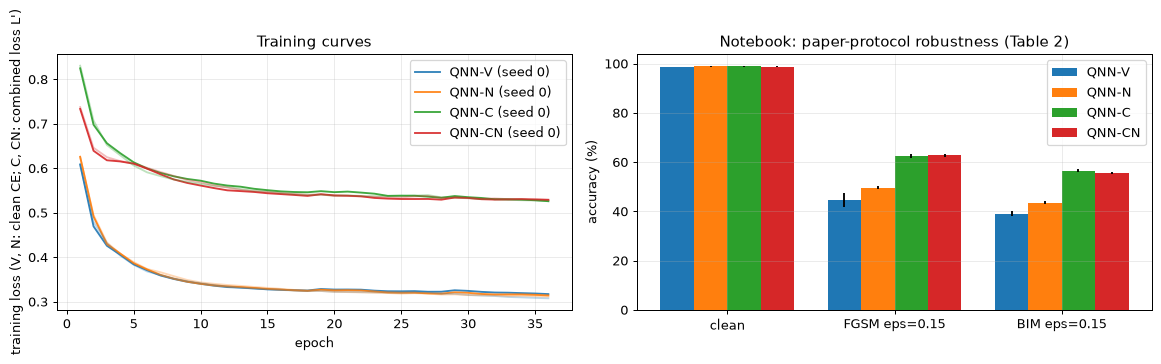

In [16]:
rows = []
for (name, s), m in MODELS.items():
    r = paper_suite(m, Xte, yte); r.update(model=name, seed=s); rows.append(r)
T2 = pd.DataFrame(rows)
cols = ["clean", "FGSM", "BIM", "clean (1 draw)", "FGSM (1 draw)", "BIM (1 draw)"]
agg = T2.groupby("model")[cols].agg(["mean", "std"]).reindex(list(SPECS))
disp = pd.DataFrame({c: [fmt_ms(T2[T2.model == n][c].values) for n in SPECS] for c in cols}, index=list(SPECS))
print(f"Test accuracy in % ({len(SEEDS)} training seed(s), {N_TEST} test images, eps = {EPS}, mean +- std over seeds)")
display(disp)
PAPER_T2 = {"QNN-V": (98.60, 32.90, 28.20), "QNN-N": (98.90, 31.25, 26.70), "QNN-C": (98.80, 48.20, 42.20), "QNN-CN": (98.70, 66.20, 62.00)}
print("\nPaper Table 2 (clean / FGSM / BIM):")
display(pd.DataFrame(PAPER_T2, index=["clean", "FGSM", "BIM"]).T)

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for (name, s), h in HIST.items():
    ax[0].plot(np.arange(1, len(h) + 1), h, label=f"{name} (seed {s})" if s == SEEDS[0] else None, alpha=0.9 if s == SEEDS[0] else 0.3,
               color={"QNN-V": "C0", "QNN-N": "C1", "QNN-C": "C2", "QNN-CN": "C3"}[name])
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("training loss (V, N: clean CE; C, CN: combined loss L')"); ax[0].legend(); ax[0].set_title("Training curves")
w = 0.2
for k, name in enumerate(SPECS):
    sub = T2[T2.model == name]
    ax[1].bar(np.arange(3) + (k - 1.5) * w, [sub[c].mean() for c in ("clean", "FGSM", "BIM")], w, yerr=[sub[c].std() if len(sub) > 1 else 0 for c in ("clean", "FGSM", "BIM")], label=name)
ax[1].set_xticks(range(3)); ax[1].set_xticklabels(["clean", f"FGSM eps={EPS}", f"BIM eps={EPS}"]); ax[1].set_ylabel("accuracy (%)"); ax[1].legend(); ax[1].set_title("Notebook: paper-protocol robustness (Table 2)")
plt.tight_layout(); plt.show()

In [17]:
# The noise coefficients beta per layer (paper Table 2, top). V and C have no noise layers, so beta receives no gradient and stays at its initial value.
PAPER_BETA = {"QNN-V": [0.2580, 0.2667, 0.2287, 0.2606, 0.2534, 0.2724, 0.2465, 0.2462, 0.2637, 0.2529],
              "QNN-N": [0.0007, 0.0009, 0.0031, 0.0008, 0.0000, 0.0048, 0.0016, 0.0006, 0.0007, 0.0006],
              "QNN-C": [0.2304, 0.2569, 0.2378, 0.2861, 0.2562, 0.2919, 0.2837, 0.2134, 0.2353, 0.2241],
              "QNN-CN": [0.0236, 0.0047, 0.0040, 0.0142, 0.0023, 0.0101, 0.0210, 0.0017, 0.0163, 0.0188]}
s0 = SEEDS[0]
BETA_TAB = pd.DataFrame({f"{n} (ours)": np.abs(MODELS[(n, s0)].beta.numpy()) for n in SPECS}, index=[f"Layer {i + 1}" for i in range(DEPTH)])
for n in ("QNN-N", "QNN-CN"): BETA_TAB[f"{n} (paper)"] = PAPER_BETA[n]
print(f"|beta| per layer after training (seed {s0}); the sign of beta is irrelevant because eta is symmetric")
display(BETA_TAB.round(4))
print("mean |beta|  ours:", {n: round(float(np.abs(MODELS[(n, s0)].beta.numpy()).mean()), 4) for n in SPECS})
print("mean |beta| paper:", {n: round(float(np.mean(PAPER_BETA[n])), 4) for n in SPECS})

|beta| per layer after training (seed 0); the sign of beta is irrelevant because eta is symmetric


,QNN-V (ours),QNN-N (ours),QNN-C (ours),QNN-CN (ours),QNN-N (paper),QNN-CN (paper)
Layer 1,0.25,0.0420,0.25,0.0535,0.0007,0.0236
Layer 2,0.25,0.0180,0.25,0.0016,0.0009,0.0047
Layer 3,0.25,0.0053,0.25,0.0193,0.0031,0.0040
Layer 4,0.25,0.0109,0.25,0.0073,0.0008,0.0142
Layer 5,0.25,0.0156,0.25,0.0038,0.0000,0.0023
Layer 6,0.25,0.0027,0.25,0.0168,0.0048,0.0101
Layer 7,0.25,0.0215,0.25,0.0041,0.0016,0.0210
Layer 8,0.25,0.0043,0.25,0.0173,0.0006,0.0017
Layer 9,0.25,0.0218,0.25,0.0078,0.0007,0.0163
Layer 10,0.25,0.0084,0.25,0.0177,0.0006,0.0188


mean |beta|  ours: {'QNN-V': 0.25, 'QNN-N': 0.015, 'QNN-C': 0.25, 'QNN-CN': 0.0149}
mean |beta| paper: {'QNN-V': 0.2549, 'QNN-N': 0.0014, 'QNN-C': 0.2516, 'QNN-CN': 0.0117}


## 5. Where the noise acts (paper Fig. 7) and robustness against growing `eps`

Fig. 7 compares four configurations on the same task: no noise layers anywhere, noise only at **test** time (a standard model with `beta = 0.25` noise added afterwards), noise only at **training** time (QNN-CN with its noise layers switched off at test time) and noise in **both** phases (QNN-CN). The curves below use BIM (3 steps of 0.05, `eps` clipped to the ball) with the paper's single-draw gradient, and the dashed curve is the *adaptive* attack that uses the exact noise-averaged gradient on QNN-CN.

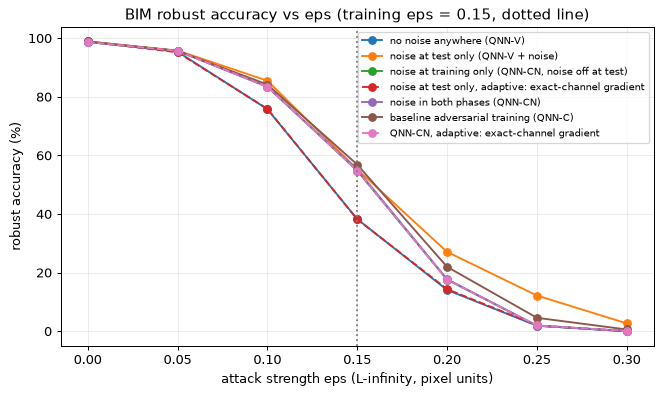

,eps=0.0,eps=0.05,eps=0.1,eps=0.15,eps=0.2,eps=0.25,eps=0.3
no noise anywhere (QNN-V),98.8,95.4,75.8,38.3,14.1,1.9,0.0
noise at test only (QNN-V + noise),98.9,95.8,85.5,55.3,27.1,12.2,2.7
"noise at training only (QNN-CN, noise off at test)",98.7,95.7,83.5,54.8,17.6,1.9,0.0
"noise at test only, adaptive: exact-channel gradient",98.9,95.2,75.9,38.2,14.4,2.0,0.0
noise in both phases (QNN-CN),98.7,95.7,83.4,55.2,17.8,1.9,0.1
baseline adversarial training (QNN-C),98.9,95.7,84.2,56.9,22.0,4.6,0.6
"QNN-CN, adaptive: exact-channel gradient",98.7,95.7,83.5,54.8,17.6,2.0,0.1


In [18]:
V0, C0, CN0 = MODELS[("QNN-V", s0)], MODELS[("QNN-C", s0)], MODELS[("QNN-CN", s0)]
CONFIGS = {"no noise anywhere (QNN-V)": (V0, "single"),
           "noise at test only (QNN-V + noise)": (QModel(V0.circ, V0.theta, V0.beta, SIGMA, True), "single"),
           "noise at training only (QNN-CN, noise off at test)": (CN0.with_noise(False), "single"),
           "noise at test only, adaptive: exact-channel gradient": (QModel(V0.circ, V0.theta, V0.beta, SIGMA, True), "exact"),
           "noise in both phases (QNN-CN)": (CN0, "single"),
           "baseline adversarial training (QNN-C)": (C0, "single"),
           "QNN-CN, adaptive: exact-channel gradient": (CN0, "exact")}
curves = {}
for lab, (mdl, mode) in CONFIGS.items():
    ys = []
    for e in EPS_GRID:
        ys.append(run_attack(mdl, Xte, yte, "none" if e == 0 else "bim", e, mode)[0] * 100)
    curves[lab] = ys
fig, ax = plt.subplots(figsize=(8.5, 4.6))
for lab, ys in curves.items():
    ax.plot(EPS_GRID, ys, "o--" if "adaptive" in lab else "o-", label=lab)
ax.axvline(EPS, color="gray", ls=":"); ax.set_xlabel("attack strength eps (L-infinity, pixel units)"); ax.set_ylabel("robust accuracy (%)")
ax.set_title("BIM robust accuracy vs eps (training eps = 0.15, dotted line)"); ax.legend(fontsize=8); plt.show()
display(pd.DataFrame(curves, index=[f"eps={e}" for e in EPS_GRID]).round(1).T)

## 6. Does the noise layer really make the model robust? Adaptive attacks and controls

The paper's argument (Section 3.2) is that noise layers "perturb the gradients and deceive gradient-based attacks". If that is the mechanism, an attacker who simply **averages over the noise** should remove the benefit. Five checks:

1. **Single draw** (the paper's attacker): one fresh noise realisation per gradient call.
2. **EOT** (expectation over transformation): the gradient of the loss averaged over `K` noise draws.
3. **Exact channel**: the gradient of the loss of the exact noise-averaged output (`K -> infinity`, no randomness left at all).
4. **PGD-20** with the exact-channel gradient (the 3-step BIM that the model is trained against is a weak attack).
5. **No-noise control**: the same trained parameters with the noise layers switched off at test time (a deterministic model), attacked normally.

If QNN-CN's gain over QNN-C were caused by gradient masking, rows 2 to 4 would be much lower than row 1, and a clean-trained model would not be fooled by random sign noise but also not a harder target than the control.

In [19]:
def adaptive_table(models, X, y, eps=EPS):
    rows = []
    for nm, mdl in models.items():
        r = {"model": nm}
        r["clean"] = run_attack(mdl, X, y, "none", 0)[0] * 100
        r["FGSM single-draw"] = run_attack(mdl, X, y, "fgsm", eps, "single")[0] * 100
        r["BIM single-draw (paper)"] = run_attack(mdl, X, y, "bim", eps, "single")[0] * 100
        if mdl.noise_on:
            r[f"BIM EOT (K={EOT_K}, {EOT_N} imgs)"] = run_attack(mdl, X, y, "bim", eps, "eot", K=EOT_K, n=EOT_N)[0] * 100
            r["BIM exact-channel"] = run_attack(mdl, X, y, "bim", eps, "exact")[0] * 100
            r["PGD-20 exact-channel"] = run_attack(mdl, X, y, "pgd", eps, "exact")[0] * 100
        else:
            r["BIM exact-channel"] = r["BIM single-draw (paper)"]            # deterministic model: identical
            r["PGD-20 exact-channel"] = run_attack(mdl, X, y, "pgd", eps, "single")[0] * 100
        g_ = torch.Generator().manual_seed(5)
        xr = (X + eps * torch.sign(torch.randn(X.shape, dtype=X.dtype, generator=g_))).clamp(0, 1)
        r["random-sign noise"] = acc_pair(mdl, xr, y)[0] * 100
        rows.append(r)
    return pd.DataFrame(rows).set_index("model")

ADAPT_MODELS = {"QNN-V": V0, "QNN-V + noise at test only": QModel(V0.circ, V0.theta, V0.beta, SIGMA, True), "QNN-N": MODELS[("QNN-N", s0)],
                "QNN-C": C0, "QNN-CN": CN0, "QNN-CN, noise OFF at test (control)": CN0.with_noise(False)}
t0 = time.time()
ADAPT = adaptive_table(ADAPT_MODELS, Xte, yte)
print(f"Robust accuracy in % at eps = {EPS} (seed {s0}; EOT columns use the first {EOT_N} test images). {time.time() - t0:.0f}s")
display(ADAPT.round(1))

Robust accuracy in % at eps = 0.15 (seed 0; EOT columns use the first 300 test images). 93s


,clean,FGSM single-draw,BIM single-draw (paper),BIM exact-channel,PGD-20 exact-channel,random-sign noise,"BIM EOT (K=20, 300 imgs)"
model,,,,,,,
QNN-V,98.8,42.6,38.3,38.3,32.5,99.2,NaN
QNN-V + noise at test only,98.9,60.9,55.3,38.2,32.6,99.2,42.7
QNN-N,98.8,50.1,43.9,43.6,38.1,98.6,45.3
QNN-C,98.9,63.1,56.9,56.9,46.8,98.9,NaN
QNN-CN,98.7,63.3,55.2,54.8,45.2,98.8,58.7
"QNN-CN, noise OFF at test (control)",98.7,62.7,54.8,54.8,45.2,98.8,NaN


In [20]:
# Gradient-masking diagnostics on QNN-CN: how well does one noisy gradient point in the true (exact-channel) gradient direction?
def grad_wrt_x(model, x, y, mode, K=1, seed=0):
    x = x.clone().requires_grad_(True)
    L = loss_fn_for(model, y, mode, K, gen=torch.Generator().manual_seed(seed))(x).sum()
    return torch.autograd.grad(L, x)[0]
n = min(200, len(yte)); xs, ys_ = Xte[:n], yte[:n]
g_ex = grad_wrt_x(CN0, xs, ys_, "exact")
diag = []
for lab, mode, K in (("single draw", "single", 1), (f"EOT K={EOT_K}", "eot", EOT_K)):
    g_ = grad_wrt_x(CN0, xs, ys_, mode, K, seed=3)
    cos = torch.nn.functional.cosine_similarity(g_, g_ex, dim=1).mean().item()
    agree = (g_.sign() == g_ex.sign()).to(torch.float64).mean().item()
    diag.append({"gradient estimate": lab, "mean cosine to exact gradient": cos, "sign agreement": agree})
print(f"QNN-CN (seed {s0}) on {n} test images; mean |beta| = {float(CN0.beta.abs().mean()):.4f}, typical noise angle beta*sigma = {float(CN0.beta.abs().mean()) * SIGMA:.4f} rad")
display(pd.DataFrame(diag).round(3))
# size of the effect of the noise on the model output (how stochastic is the trained model, really?)
zs = torch.stack([CN0.z(Xte[:200], gen=torch.Generator().manual_seed(k)) for k in range(30)])
print(f"QNN-CN: std of <Z> across 30 noise draws, averaged over images = {zs.std(0).mean():.4f} (|<Z>| averages {zs.mean(0).abs().mean():.3f}); "
      f"label flips between a single draw and the exact average: {((zs[0] < 0) != (CN0.z_exact(Xte[:200]) < 0)).to(torch.float64).mean() * 100:.2f} % of images")

QNN-CN (seed 0) on 200 test images; mean |beta| = 0.0149, typical noise angle beta*sigma = 0.0066 rad


,gradient estimate,mean cosine to exact gradient,sign agreement
0,single draw,0.998,0.973
1,EOT K=20,1.000,0.994


QNN-CN: std of <Z> across 30 noise draws, averaged over images = 0.0046 (|<Z>| averages 0.461); label flips between a single draw and the exact average: 0.00 % of images


## 7. Effect of the noise variance `sigma^2` (paper Fig. 8)

QNN-CN is retrained for `sigma^2 = 2 pi / 2^k` (the paper's largest value, labelled "2pi21" in the extracted text, is `k = 1`, i.e. `sigma^2 = pi`). One seed and a shorter budget (`EPOCHS_EXTRA`) per point.

k=1: sigma^2=3.142 trained in 25s


k=3: sigma^2=0.785 trained in 27s


k=5: sigma^2=0.196 trained in 27s


k=7: sigma^2=0.049 trained in 27s


,sigma2,mean_abs_beta,noise_angle,clean,FGSM,BIM,BIM exact-channel,clean (1 draw),BIM (1 draw)
k,,,,,,,,,
1,3.142,0.011,0.020,98.8,50.5,43.0,42.1,98.8,42.4
3,0.785,0.012,0.011,98.8,57.4,51.1,50.7,98.9,50.8
5,0.196,0.017,0.008,98.9,56.3,48.6,48.7,98.9,48.6
7,0.049,0.034,0.008,99.0,51.3,42.9,42.9,99.0,43.1


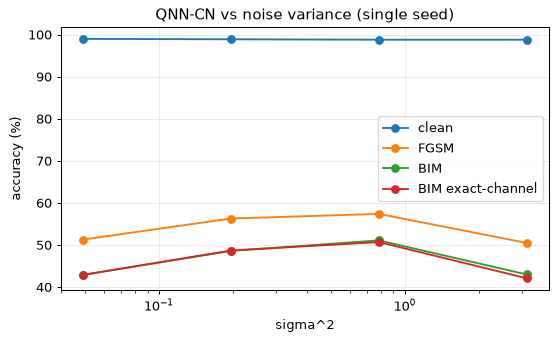

In [21]:
rows = []
for k in SIGMA_K:
    s2 = 2 * math.pi / 2 ** k
    t0 = time.time()
    m, h = train_qnn(CIRC, Xtr, ytr, noise=True, combined=True, sigma=math.sqrt(s2), epochs=EPOCHS_EXTRA, lr=LR, bs=BS, eps=EPS, seed=0, beta0=BETA0, name=f"CN k={k}", verbose=False)
    r = paper_suite(m, Xte, yte)
    r["BIM exact-channel"] = run_attack(m, Xte, yte, "bim", EPS, "exact")[0] * 100
    r.update(k=k, sigma2=s2, mean_abs_beta=float(m.beta.abs().mean()), noise_angle=float(m.beta.abs().mean()) * math.sqrt(s2)); rows.append(r)
    print(f"k={k}: sigma^2={s2:.3f} trained in {time.time() - t0:.0f}s")
SW = pd.DataFrame(rows).set_index("k")
display(SW[["sigma2", "mean_abs_beta", "noise_angle", "clean", "FGSM", "BIM", "BIM exact-channel", "clean (1 draw)", "BIM (1 draw)"]].round(3))
fig, ax = plt.subplots(figsize=(7, 3.8))
for c in ("clean", "FGSM", "BIM", "BIM exact-channel"): ax.plot(SW.sigma2, SW[c], "o-", label=c)
ax.set_xscale("log"); ax.set_xlabel("sigma^2"); ax.set_ylabel("accuracy (%)"); ax.legend(); ax.set_title("QNN-CN vs noise variance (single seed)"); plt.show()

## 8. Circuit depth (paper Fig. 9)

The paper finds that deeper circuits are more robust and that its method beats the baseline at every depth. QNN-C and QNN-CN are retrained at the extra depths in `DEPTHS` (and the main depth 10 is reused, trained with the larger `EPOCHS` budget).

In [22]:
rows = []
for d in DEPTHS:
    cd = build_qnn(N_QUBITS, d)
    for nm in ("QNN-C", "QNN-CN"):
        t0 = time.time()
        m, h = train_qnn(cd, Xtr, ytr, sigma=SIGMA, epochs=EPOCHS_EXTRA, lr=LR, bs=BS, eps=EPS, seed=0, beta0=BETA0, name=f"{nm} d={d}", verbose=False, **SPECS[nm])
        r = paper_suite(m, Xte, yte); r.update(depth=d, model=nm, params=cd.n_theta + (cd.n_noise if SPECS[nm]["noise"] else 0), budget=f"{EPOCHS_EXTRA} ep")
        rows.append(r); print(f"depth {d} {nm}: {time.time() - t0:.0f}s")
for nm in ("QNN-C", "QNN-CN"):
    r = paper_suite(MODELS[(nm, s0)], Xte, yte); r.update(depth=DEPTH, model=nm, params=CIRC.n_theta + (CIRC.n_noise if SPECS[nm]["noise"] else 0), budget=f"{EPOCHS} ep"); rows.append(r)
DP = pd.DataFrame(rows).sort_values(["depth", "model"]).set_index(["depth", "model"])
display(DP[["params", "budget", "clean", "FGSM", "BIM"]].round(1))

depth 5 QNN-C: 14s


depth 5 QNN-CN: 14s


depth 20 QNN-C: 50s


depth 20 QNN-CN: 52s


params budget  clean  FGSM   BIM
depth model                                   
5     QNN-C      120  12 ep   97.7  33.4  26.6
      QNN-CN     125  12 ep   98.3  26.3  20.6
10    QNN-C      240  36 ep   98.9  63.1  56.9
      QNN-CN     250  36 ep   98.7  63.3  55.2
20    QNN-C      480  12 ep   98.7  74.7  69.2
      QNN-CN     500  12 ep   98.7  73.2  66.0

## 9. QCNN (paper Fig. 3b, Table 3)

Same three comparisons (no defence, baseline adversarial training, this work) on the QCNN of the drawing above. A noise layer is placed before each convolution stage. One seed, `EPOCHS_EXTRA` epochs.

In [23]:
rows = []; QC = {}
for lab, nm in (("No defence", "QNN-V"), ("Baseline", "QNN-C"), ("This work", "QNN-CN")):
    t0 = time.time()
    m, h = train_qnn(CIRC_QCNN, Xtr, ytr, sigma=SIGMA, epochs=EPOCHS_EXTRA, lr=LR, bs=BS, eps=EPS, seed=0, beta0=BETA0, name="QCNN " + lab, verbose=False, **SPECS[nm])
    QC[lab] = m
    r = paper_suite(m, Xte, yte); r["defence"] = lab; rows.append(r)
    print(f"QCNN {lab}: {time.time() - t0:.0f}s, beta = {m.beta.numpy().round(3)}")
T3 = pd.DataFrame(rows).set_index("defence")
display(T3[["clean", "FGSM", "BIM", "clean (1 draw)", "BIM (1 draw)"]].round(1))
PAPER_T3 = {"No defence": (97.75, 20.50, 17.00), "Baseline": (97.10, 55.00, 45.30), "This work": (98.75, 61.35, 53.25)}
display(pd.DataFrame(PAPER_T3, index=["clean", "FGSM", "BIM"]).T)
# adaptive check on the QCNN as well
ad = {}
for lab in ("Baseline", "This work"):
    m = QC[lab]
    ad[lab] = {"BIM single-draw": run_attack(m, Xte, yte, "bim", EPS, "single")[0] * 100,
               "BIM exact-channel": run_attack(m, Xte, yte, "bim", EPS, "exact")[0] * 100 if m.noise_on else np.nan,
               f"BIM EOT K={EOT_K} ({EOT_N} imgs)": run_attack(m, Xte, yte, "bim", EPS, "eot", K=EOT_K, n=EOT_N)[0] * 100 if m.noise_on else np.nan}
display(pd.DataFrame(ad).T.round(1))

QCNN No defence: 17s, beta = [0.25 0.25 0.25]


QCNN Baseline: 45s, beta = [0.25 0.25 0.25]


QCNN This work: 56s, beta = [-0.028  0.051  0.122]


,clean,FGSM,BIM,clean (1 draw),BIM (1 draw)
defence,,,,,
No defence,98.4,34.8,31.9,98.4,31.9
Baseline,97.8,53.4,45.6,97.8,45.6
This work,97.9,52.0,44.3,98.0,44.4


,clean,FGSM,BIM
No defence,97.75,20.50,17.00
Baseline,97.10,55.00,45.30
This work,98.75,61.35,53.25


,BIM single-draw,BIM exact-channel,BIM EOT K=20 (300 imgs)
Baseline,45.6,NaN,NaN
This work,44.3,44.2,46.3


## 10. Black-box transfer attacks (paper Table 4)

A classical source model (FNN: 512-53 hidden units with two dropout layers; CNN: 64@8x8, 128@4x4, 64@2x2 filters) is trained on the same 400 training images, FGSM / BIM / MIM examples (`eps = 0.15`) are crafted on the source, and the quantum models classify them. The source models know nothing about the QNN.

In [24]:
SRC = {}
for nm, cls in (("FNN", FNNSrc), ("CNN", CNNSrc)):
    t0 = time.time(); SRC[nm] = train_source(cls(), Xtr, ytr, SRC_EPOCHS, seed=SEED)
    print(f"{nm} source: clean test accuracy {accuracy(SRC[nm], Xte, yte, 'draw') * 100:.1f} %  ({time.time() - t0:.0f}s)")
rows = []
for sn, src in SRC.items():
    for kind in ("fgsm", "bim", "mim"):
        xa = attack_linf(loss_fn_for(src, yte, "single"), Xte, EPS, **make_attack(kind, EPS))
        r = {"source": sn, "attack": kind.upper(), "source acc (white-box)": accuracy(src, xa, yte, "draw") * 100}
        for lab, mdl in (("No defence (QNN-V)", V0), ("Baseline (QNN-C)", C0), ("This work (QNN-CN)", CN0)):
            r[lab] = acc_pair(mdl, xa, yte)[0] * 100
        rows.append(r)
T4 = pd.DataFrame(rows).set_index(["source", "attack"])
display(T4.round(1))
PAPER_T4 = pd.DataFrame({("CNN", "FGSM"): (63.9, 95.7, 96.6), ("CNN", "BIM"): (66.8, 96.0, 97.6), ("CNN", "MIM"): (67.0, 95.1, 96.6),
                         ("FNN", "FGSM"): (44.6, 82.8, 88.4), ("FNN", "BIM"): (43.9, 86.5, 92.2), ("FNN", "MIM"): (37.8, 84.1, 90.2)},
                        index=["No defence", "Baseline", "This work"]).T
print("Paper Table 4:"); display(PAPER_T4)

FNN source: clean test accuracy 99.4 %  (3s)


CNN source: clean test accuracy 99.5 %  (59s)


source acc (white-box)  No defence (QNN-V)  Baseline (QNN-C)  \
source attack                                                                 
FNN    FGSM                      29.8                79.9              89.5   
       BIM                       26.9                79.2              89.2   
       MIM                       28.4                79.1              89.1   
CNN    FGSM                      60.1                88.6              91.8   
       BIM                       59.5                87.9              92.0   
       MIM                       59.7                87.9              91.9   

               This work (QNN-CN)  
source attack                      
FNN    FGSM                  90.4  
       BIM                   90.0  
       MIM                   90.1  
CNN    FGSM                  90.6  
       BIM                   91.0  
       MIM                   91.0

Paper Table 4:


No defence  Baseline  This work
CNN FGSM        63.9      95.7       96.6
    BIM         66.8      96.0       97.6
    MIM         67.0      95.1       96.6
FNN FGSM        44.6      82.8       88.4
    BIM         43.9      86.5       92.2
    MIM         37.8      84.1       90.2

## 11. A classical model with noise layers on identical inputs

Is the effect specific to the quantum circuit? A small classical MLP (`256 -> 64 -> 1`, same normalised input vector, trained with the same Adam/batch/loss/BIM recipe) gets the analogous noise layers: `h <- h + beta * eta * rms(h)` with trainable `beta` (init 0.25) before each linear layer, so the noise is *relative* to the signal. Variants: standard (V), Gaussian-noise augmentation with a fixed `beta` and no adversarial loss (G, the "Gaussian data augmentation" baseline of the paper), adversarial training (C), adversarial training with trainable noise layers (CN). The classical models are attacked with the single-draw gradient (paper protocol) and with EOT, and classified by the mean of 50 noise draws.

In [25]:
CLS = {}
for nm, kw in (("MLP-V", dict(noise=False, combined=False)), ("MLP-G (Gaussian aug.)", dict(noise=True, combined=False, freeze_beta=True)),
               ("MLP-C", dict(noise=False, combined=True)), ("MLP-CN", dict(noise=True, combined=True))):
    t0 = time.time(); CLS[nm] = train_cmlp(Xtr, ytr, epochs=CLS_EPOCHS, lr=0.005, bs=BS, eps=EPS, seed=SEED, name=nm, **kw)
    print(f"{nm}: {time.time() - t0:.0f}s")
rows = []
for nm, m in CLS.items():
    r = {"model": nm, "mean |beta|": float(m.net.beta.abs().mean()) if m.noise_on else np.nan}
    r["clean"] = run_attack(m, Xte, yte, "none", 0)[0] * 100
    r["BIM single-draw"] = run_attack(m, Xte, yte, "bim", EPS, "single")[0] * 100
    r[f"BIM EOT K={EOT_K} ({EOT_N} imgs)"] = run_attack(m, Xte, yte, "bim", EPS, "eot", K=EOT_K, n=EOT_N)[0] * 100 if m.noise_on else r["BIM single-draw"]
    rows.append(r)
CLS_T = pd.DataFrame(rows).set_index("model")
display(CLS_T.round(2))

MLP-V: 1s


MLP-G (Gaussian aug.): 2s


MLP-C: 4s


MLP-CN: 9s


,mean |beta|,clean,BIM single-draw,BIM EOT K=20 (300 imgs)
model,,,,
MLP-V,NaN,99.4,40.5,40.5
MLP-G (Gaussian aug.),0.25,99.4,36.9,17.0
MLP-C,NaN,99.5,95.3,95.3
MLP-CN,0.02,99.5,95.2,96.0


## 12. Side by side with the paper

Every number the notebook can test is shown next to the paper's value. Verdict rule: **reproduced** if within 2 accuracy points, otherwise **not reached** / **exceeded** with the gap. Qualitative claims get a verdict from the sign and size of the measured effect (a difference counts as an effect only if it exceeds 2 points and, where several seeds exist, the seed spread).

In [26]:
rows = []
mean_of = lambda name, col: float(T2[T2.model == name][col].mean())
for name in SPECS:
    for j, col in enumerate(("clean", "FGSM", "BIM")):
        pv, nv = PAPER_T2[name][j], mean_of(name, col)
        rows.append(("Table 2", f"{name} {col}", pv, round(nv, 1), verdict(nv, pv)))
for lab in PAPER_T3:
    for j, col in enumerate(("clean", "FGSM", "BIM")):
        pv, nv = PAPER_T3[lab][j], float(T3.loc[lab, col])
        rows.append(("Table 3 (QCNN)", f"{lab} {col}", pv, round(nv, 1), verdict(nv, pv)))
for (sn, kind), pv3 in PAPER_T4.iterrows():
    for j, lab in enumerate(("No defence (QNN-V)", "Baseline (QNN-C)", "This work (QNN-CN)")):
        nv = float(T4.loc[(sn, kind), lab])
        rows.append(("Table 4", f"{sn} {kind} {lab.split(' (')[0]}", float(pv3.iloc[j]), round(nv, 1), verdict(nv, float(pv3.iloc[j]))))
numeric = pd.DataFrame(rows, columns=["Where", "Quantity (accuracy %)", "Paper", "Notebook", "Verdict"])
pd.set_option("display.max_rows", 200, "display.width", 160)
display(numeric)
cnt = numeric.Verdict.str.split(" ").str[0].value_counts()
print("Verdicts over the", len(numeric), "numeric entries:", dict(cnt))

,Where,Quantity (accuracy %),Paper,Notebook,Verdict
0,Table 2,QNN-V clean,98.60,98.8,reproduced
1,Table 2,QNN-V FGSM,32.90,44.7,exceeded (+11.8)
2,Table 2,QNN-V BIM,28.20,39.0,exceeded (+10.8)
3,Table 2,QNN-N clean,98.90,98.8,reproduced
4,Table 2,QNN-N FGSM,31.25,49.7,exceeded (+18.5)
5,Table 2,QNN-N BIM,26.70,43.5,exceeded (+16.8)
6,Table 2,QNN-C clean,98.80,98.8,reproduced
7,Table 2,QNN-C FGSM,48.20,62.5,exceeded (+14.3)
8,Table 2,QNN-C BIM,42.20,56.5,exceeded (+14.3)
9,Table 2,QNN-CN clean,98.70,98.8,reproduced


Verdicts over the 39 numeric entries: {'exceeded': np.int64(17), 'reproduced': np.int64(11), 'not': np.int64(11)}


In [27]:
# Qualitative claims, each with an explicit verdict computed from the measurements above.
def eff(a, b, spread=0.0): return (a - b) > max(2.0, spread)
fg = lambda n, c: T2[T2.model == n][c]
claims = []
cn_fgsm, c_fgsm = fg("QNN-CN", "FGSM"), fg("QNN-C", "FGSM"); cn_bim, c_bim = fg("QNN-CN", "BIM"), fg("QNN-C", "BIM")
sp = max(cn_fgsm.std() if len(cn_fgsm) > 1 else 0, c_fgsm.std() if len(c_fgsm) > 1 else 0)
claims.append(("Adversarial training (C) beats no defence (V) under FGSM/BIM",
               f"FGSM {fg('QNN-C','FGSM').mean():.1f} vs {fg('QNN-V','FGSM').mean():.1f}; BIM {fg('QNN-C','BIM').mean():.1f} vs {fg('QNN-V','BIM').mean():.1f}",
               "reproduced" if eff(fg('QNN-C','BIM').mean(), fg('QNN-V','BIM').mean()) else "not reached"))
claims.append(("Noise only, no adversarial loss (N) gives no robustness; beta collapses",
               f"N BIM {fg('QNN-N','BIM').mean():.1f} vs V {fg('QNN-V','BIM').mean():.1f}; mean|beta| N = {np.mean([float(MODELS[('QNN-N', s)].beta.abs().mean()) for s in SEEDS]):.4f}",
               "reproduced" if (not eff(fg('QNN-N','BIM').mean(), fg('QNN-V','BIM').mean()) and np.mean([float(MODELS[('QNN-N', s)].beta.abs().mean()) for s in SEEDS]) < 0.05) else "not reached"))
claims.append(("CN beats the adversarial-training baseline C on FGSM (paper +18.0) and BIM (paper +19.8) under the paper's attacker",
               f"FGSM {cn_fgsm.mean() - c_fgsm.mean():+.1f}, BIM {cn_bim.mean() - c_bim.mean():+.1f} points",
               "reproduced" if (eff(cn_fgsm.mean(), c_fgsm.mean(), sp) and eff(cn_bim.mean(), c_bim.mean(), sp)) else "not reached"))
claims.append(("CN keeps clean accuracy (>= 97 %)", f"{fg('QNN-CN','clean').mean():.1f} %", "reproduced" if fg('QNN-CN','clean').mean() >= 97 else "not reached"))
claims.append(("beta of CN settles at small positive values (0.002 to 0.024)", f"mean |beta| CN = {np.mean([float(MODELS[('QNN-CN', s)].beta.abs().mean()) for s in SEEDS]):.4f}",
               "reproduced" if 0.0005 <= np.mean([float(MODELS[('QNN-CN', s)].beta.abs().mean()) for s in SEEDS]) <= 0.05 else "not reached"))
v_t, tn = curves["noise at test only (QNN-V + noise)"], curves["noise at training only (QNN-CN, noise off at test)"]; bo = curves["noise in both phases (QNN-CN)"]; nn_ = curves["no noise anywhere (QNN-V)"]
i = EPS_GRID.index(EPS)
claims.append(("Fig. 7: noise at test only lowers clean accuracy and does not help", f"clean {v_t[0]:.1f} vs {nn_[0]:.1f}; BIM@0.15 {v_t[i]:.1f} vs {nn_[i]:.1f}", "reproduced" if (v_t[0] < nn_[0] - 2 and v_t[i] <= nn_[i] + 2) else "not reached"))
claims.append(("Fig. 7: noise at training only is clearly less robust than noise in both phases", f"BIM@0.15 {tn[i]:.1f} vs both {bo[i]:.1f}", "reproduced" if bo[i] - tn[i] > 2 else "not reached (no difference)"))
adv = ADAPT.loc["QNN-CN"]
gap = adv["BIM single-draw (paper)"] - adv["BIM exact-channel"]
claims.append(("Section 3.2: the gain of the noise layer comes from perturbing the attacker's gradients (testable: it should vanish for an attacker who averages the noise)",
               f"QNN-CN BIM: single-draw {adv['BIM single-draw (paper)']:.1f}, exact-channel {adv['BIM exact-channel']:.1f} (gap {gap:+.1f}); QNN-C BIM {ADAPT.loc['QNN-C', 'BIM single-draw (paper)']:.1f}",
               "supported (gradient masking)" if gap > 5 else "not supported: no gradient masking at this noise level"))
adv_c = ADAPT.loc["QNN-C"]
claims.append(("Added check: does CN still beat the baseline C against the strongest attack here (PGD-20 with the exact-channel gradient)?",
               f"PGD-20: CN {adv['PGD-20 exact-channel']:.1f} vs C {adv_c['PGD-20 exact-channel']:.1f}; BIM exact-channel: CN {adv['BIM exact-channel']:.1f} vs C {adv_c['BIM exact-channel']:.1f}",
               "yes (still better by > 2 points)" if adv['PGD-20 exact-channel'] - adv_c['PGD-20 exact-channel'] > 2 else "no (advantage not larger than 2 points)"))
vt = ADAPT.loc["QNN-V + noise at test only"]
claims.append(("Added check: noise at test time alone (QNN-V + noise) looks robust to the single-draw attacker; is it?",
               f"BIM single-draw {vt['BIM single-draw (paper)']:.1f} vs exact-channel {vt['BIM exact-channel']:.1f} (QNN-V without noise: {ADAPT.loc['QNN-V', 'BIM single-draw (paper)']:.1f})",
               "gradient masking (apparent gain disappears)" if vt['BIM single-draw (paper)'] - vt['BIM exact-channel'] > 5 else "no masking detected"))
claims.append(("Fig. 8/9, Table 3/4: stable in sigma^2, depth, QCNN and transfer attacks", "see sections 7 to 10", "see the tables above (per entry verdicts in the numeric table)"))
claims.append(("Table 1 / Fig. 4 to 6 (moons, Ising ground states)", "not run", "cannot be checked"))
QUAL = pd.DataFrame(claims, columns=["Claim", "Evidence in this notebook", "Verdict"])
pd.set_option("display.max_colwidth", 200)
display(QUAL)

,Claim,Evidence in this notebook,Verdict
0,Adversarial training (C) beats no defence (V) under FGSM/BIM,FGSM 62.5 vs 44.7; BIM 56.5 vs 39.0,reproduced
1,"Noise only, no adversarial loss (N) gives no robustness; beta collapses",N BIM 43.5 vs V 39.0; mean|beta| N = 0.0107,not reached
2,CN beats the adversarial-training baseline C on FGSM (paper +18.0) and BIM (paper +19.8) under the paper's attacker,"FGSM +0.3, BIM -1.0 points",not reached
3,CN keeps clean accuracy (>= 97 %),98.8 %,reproduced
4,beta of CN settles at small positive values (0.002 to 0.024),mean |beta| CN = 0.0149,reproduced
5,Fig. 7: noise at test only lowers clean accuracy and does not help,clean 98.9 vs 98.8; BIM@0.15 55.3 vs 38.3,not reached
6,Fig. 7: noise at training only is clearly less robust than noise in both phases,BIM@0.15 54.8 vs both 55.2,not reached (no difference)
7,Section 3.2: the gain of the noise layer comes from perturbing the attacker's gradients (testable: it should vanish for an attacker who averages the noise),"QNN-CN BIM: single-draw 55.2, exact-channel 54.8 (gap +0.4); QNN-C BIM 56.9",not supported: no gradient masking at this noise level
8,Added check: does CN still beat the baseline C against the strongest attack here (PGD-20 with the exact-channel gradient)?,PGD-20: CN 45.2 vs C 46.8; BIM exact-channel: CN 54.8 vs C 56.9,no (advantage not larger than 2 points)
9,Added check: noise at test time alone (QNN-V + noise) looks robust to the single-draw attacker; is it?,BIM single-draw 55.3 vs exact-channel 38.2 (QNN-V without noise: 38.3),gradient masking (apparent gain disappears)


## 13. Reading the paper critically

Numbers below are from the saved run (`FAST_MODE = False`, 2 training seeds for Table 2, 1000 test images, 36 epochs instead of 200; one standard error of a 1000-image accuracy is about 1.5 points).

**What reproduced.**
* Clean accuracy about 98.8 % for every model, as in the paper (98.6 to 98.9 %).
* Adversarial training works: QNN-C reaches FGSM 62.5 % / BIM 56.5 % against 44.7 % / 39.0 % for the undefended QNN-V (the direction and the ordering of the paper's Table 2).
* The `beta` dynamics: without noise layers `beta` receives no gradient and stays at 0.25; with noise layers it collapses to about 0.01 to 0.015 (paper: 0.001 for QNN-N, 0.012 for QNN-CN).
* QCNN baseline numbers (FGSM 53.4 / BIM 45.6 against the paper's 55.0 / 45.3).

**What did not reproduce: the headline claim.** The paper reports QNN-CN 18 to 20 points above the adversarial-training baseline. Here QNN-CN minus QNN-C is **+0.3 points (FGSM) and -1.0 points (BIM)**, inside the seed spread, and the same holds for the QCNN (CN 52.0 / 44.3 against C 53.4 / 45.6), for depth 5, 10 and 20, and for the transfer attacks (at most 1 point). Our QNN-C baseline is much stronger than the paper's (BIM 56.5 against 42.2) while our undefended model is also less vulnerable (39.0 against 28.2); our QNN-CN is below the paper's (55.5 against 62.0). Possible reasons for the different baselines are the perturbation space (pixel space here, unspecified in the paper), adversarial examples crafted per mini-batch against the current model, and the optimiser settings; none of them is documented in the paper.

**Why the noise layer does not help here.** The optimiser drives `beta` to about 0.015, so the noise angle `beta * sigma` is about 0.007 rad and the standard deviation of `<Z>` over noise draws is about 0.005: the "noisy" model is practically deterministic. Consistently, (i) switching the noise off at test time changes nothing (54.8 % against 55.2 %), which also contradicts the Fig. 7 claim that noise at training time alone is much worse than noise in both phases; (ii) a single noisy gradient has cosine 0.998 with the exact noise-averaged gradient, so there is nothing to mask; (iii) the exact-channel attack, EOT and PGD-20 all give the same robustness as the paper's single-draw attack, and PGD-20 gives QNN-CN 45.2 % against 46.8 % for QNN-C. The gain of QNN-CN over QNN-V comes from the adversarial loss, not from the noise.

**Gradient masking is real, but only where the noise is large and imposed.** Adding noise layers with `beta = 0.25` to the *undefended* model at test time raises its apparent BIM robustness from 38.3 % to 55.3 % against the paper's single-draw attacker, yet an attacker who uses the exact noise-averaged gradient brings it straight back to 38.2 %, the value without any noise. That 17-point "defence" is pure gradient masking, exactly the failure mode that earlier papers in this corpus found for "quantum is more robust" claims; the same attacker gap exists for the classical MLP with Gaussian augmentation (BIM 36.9 % single-draw against 17.0 % with EOT). The paper's trainable `beta` removes this artefact, but also removes the benefit.

**Protocol weaknesses worth knowing.** (1) Three BIM steps are a weak attack: for every model, PGD-20 lowers robust accuracy by about 10 points (QNN-C 56.9 to 46.8 %), so the Table 2 numbers overstate robustness in absolute terms. (2) The same classical recipe on identical inputs is far more robust: an MLP with adversarial training reaches 95 % BIM accuracy against 56 % for the QNN, so "robust quantum models" need a classical reference. (3) The black-box transfer numbers depend strongly on how `eps` is defined (undefended QNN 79 to 88 % here against 38 to 67 % in the paper). (4) The paper's data are "available on reasonable request" and its code is not public, so unspecified details (perturbation space, CNOT pattern, `sigma^2` digits, per-epoch or per-batch adversarial examples) could not be matched.

**Not checked.** Table 1 and Figs 4 to 6 (moons and Ising ground states) were not run (the circuit for 2-D inputs is not specified; Fig. 6 reports curves only). Fig. 2 and 5 (embedding-space visualisations) were not redrawn. Budgets are far below the paper's 200 epochs, so a longer run could narrow, but is unlikely to open, an 18-point gap given the `beta` collapse.

## 14. Exercises

1. Change `SIGMA_K` to `(1, 2, 3, 4, 5, 6, 7)` and plot clean and robust accuracy against `sigma^2`. Where does the learned `beta` stop shrinking the noise?
2. Freeze `beta = 1.0` (`beta0=1.0` and drop it from the optimiser in `train_qnn`) so that the noise cannot be trained away. Does QNN-CN become more robust against the exact-channel attack, and what happens to clean accuracy?
3. Replace the CNOT ring by a line of CNOTs `0->1, ..., 6->7` (edit `build_qnn`) and repeat Table 2. How much of the result depends on the unspecified entangler?
4. Attack with `eps = 0.3` and 40 PGD steps using the exact-channel gradient. Which defence collapses first?
5. Use `heisenberg_matrix` to compute the exact output of QNN-CN for a test image under the *adversarial* noise level you choose per layer; can you find noise strengths for which the exact model is both accurate and robust?